# New BRIDGES variant set: which genes, and where in the genes?

`data/new_bridges_data/bridges_34genes.csv` lists variants as `VariantID;Chromosome;Position;Ref;Alt`
in **GRCh37** coordinates (e.g. BRCA2 at chr13:32.89 Mb), with no gene or consequence column.

Steps:
1. Lift the variants to hg38, so positions match GENCODE v46 and AlphaGenome.
2. Annotate with VEP (RefSeq cache, GRCh38), using each BRIDGES gene's **MANE Select** transcript.
3. Assign each variant to a BRIDGES gene and a region class (coding, splice, UTR, intron, promoter, ...).
4. Statistics per gene and per region, and a genome track plot per gene.

In [1]:
import io
import pathlib
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyliftover import LiftOver

ROOT = pathlib.Path('/storage/mathelierarea/processed/eirikhoy/action_var')
VARIANTS_CSV = ROOT / 'data/new_bridges_data/bridges_34genes.csv'
VCF_HG38 = ROOT / 'results/bridges34_new_variants_hg38.vcf'
VEP_OUT = ROOT / 'results/bridges34_new_variants_vep_grch38.txt'
FIGDIR = pathlib.Path('new_bridges34_figures')
FIGDIR.mkdir(exist_ok=True)

# The 34 BRIDGES genes, current HGNC names (FAM175A=ABRAXAS1, BRE=BABAM2, MRE11A=MRE11).
BRIDGES_GENES = [
    'ABRAXAS1', 'AKT1', 'ATM', 'BABAM2', 'BARD1', 'BRCA1', 'BRCA2', 'BRIP1', 'CDH1',
    'CHEK2', 'EPCAM', 'FANCC', 'FANCM', 'GEN1', 'MEN1', 'MLH1', 'MRE11', 'MSH2', 'MSH6',
    'MUTYH', 'NBN', 'NF1', 'PALB2', 'PIK3CA', 'PMS2', 'PTEN', 'RAD50', 'RAD51C',
    'RAD51D', 'RECQL', 'RINT1', 'STK11', 'TP53', 'XRCC2',
]

# Region classes in 5'->3' order, each with a fixed categorical colour.
REGIONS = {
    'upstream (1-5 kb)': '#2a78d6',
    'promoter (≤1 kb)': '#eb6834',
    "5' UTR": '#1baf7a',
    'coding': '#eda100',
    'splice site / region': '#e87ba4',
    'intron': '#008300',
    "3' UTR": '#6250d6',
    'downstream (≤5 kb)': '#e34948',
    'distal (>5 kb)': '#b5b4ad',
}

INK, SECONDARY, MUTED, GRID, AXIS, BLUE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#2a78d6'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': SECONDARY,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelcolor': SECONDARY, 'ytick.labelcolor': SECONDARY,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.titlesize': 16, 'figure.titleweight': 'bold',
})


def save(fig, name):
    fig.savefig(FIGDIR / f'{name}.png', dpi=200, bbox_inches='tight')

## 1. Load the variants

In [2]:
raw = pd.read_csv(VARIANTS_CSV, sep=';', encoding='utf-8-sig')
variants = raw.drop_duplicates('VariantID').copy()
variants['type'] = np.select(
    [(variants.Ref.str.len() == 1) & (variants.Alt.str.len() == 1),
     variants.Ref.str.len() > variants.Alt.str.len(),
     variants.Ref.str.len() < variants.Alt.str.len()],
    ['SNV', 'deletion', 'insertion'], 'MNV / complex',
)
print(f'{len(raw):,} rows, {len(raw) - len(variants)} exact duplicates removed -> {len(variants):,} unique variants')
variants.type.value_counts().to_frame('variants')

25,172 rows, 56 exact duplicates removed -> 25,116 unique variants


,variants
type,
SNV,23395
deletion,1242
insertion,405
MNV / complex,74


## 2. Lift to hg38 and annotate with VEP

VEP runs from the project's container with the local RefSeq cache (offline), once; the output is cached
in `results/`. `--use_given_ref` keeps the alleles from the input file.

In [3]:
lift = LiftOver('hg19', 'hg38')


def to_hg38(chrom, pos):
    hit = lift.convert_coordinate(f'chr{chrom}', int(pos) - 1)
    if not hit or hit[0][0] != f'chr{chrom}' or hit[0][2] != '+':
        return np.nan
    return hit[0][1] + 1


variants['chrom'] = 'chr' + variants.Chromosome.astype(str)
variants['pos'] = [to_hg38(c, p) for c, p in zip(variants.Chromosome, variants.Position)]
print(f'{variants.pos.isna().sum()} variants did not lift over')
variants = variants.dropna(subset=['pos']).astype({'pos': int}).sort_values(['chrom', 'pos'])

if not VEP_OUT.exists():
    with open(VCF_HG38, 'w') as f:
        f.write('##fileformat=VCFv4.2\n#CHROM\tPOS\tID\tREF\tALT\tQUAL\tFILTER\tINFO\n')
        for v in variants.itertuples():
            f.write(f'{v.chrom}\t{v.pos}\t{v.VariantID}\t{v.Ref}\t{v.Alt}\t.\t.\t.\n')
    subprocess.run([
        'singularity', 'exec', '-B', '/storage', str(ROOT / 'containers/ensembl-vep.sif'), 'vep',
        '--input_file', str(VCF_HG38), '--format', 'vcf', '--offline', '--cache',
        '--dir_cache', str(ROOT / 'resources'), '--refseq', '--use_given_ref',
        '--assembly', 'GRCh38', '--cache_version', '111', '--symbol', '--mane', '--canonical',
        '--biotype', '--tab', '--no_stats', '--fork', '8', '--force_overwrite',
        '--output_file', str(VEP_OUT),
    ], check=True, cwd=ROOT)

text = ''.join(line for line in open(VEP_OUT) if not line.startswith('##'))
vep = pd.read_csv(io.StringIO(text), sep='\t', low_memory=False).rename(columns={'#Uploaded_variation': 'VariantID'})
print(f'{len(vep):,} variant-transcript rows for {vep.VariantID.nunique():,} variants')

0 variants did not lift over
1,116,052 variant-transcript rows for 25,116 variants


## 3. Assign each variant to a BRIDGES gene and a region class

Consequences are taken on the MANE Select transcript of a BRIDGES gene. VEP reports genes within 5 kb;
when two BRIDGES genes qualify (e.g. EPCAM and MSH2), the one the variant lies inside wins, then the nearest.
Variants further than 5 kb from every BRIDGES gene are "distal" and assigned to the nearest TSS.

Priority when VEP gives several terms: canonical splice site > coding > splice region > UTR > intron.

In [4]:
CODING_TERMS = {
    'missense_variant': 'missense', 'synonymous_variant': 'synonymous',
    'stop_gained': 'stop gained', 'frameshift_variant': 'frameshift',
    'start_lost': 'start / stop lost', 'stop_lost': 'start / stop lost',
    'inframe_insertion': 'in-frame indel', 'inframe_deletion': 'in-frame indel',
    'protein_altering_variant': 'other coding', 'stop_retained_variant': 'synonymous',
    'start_retained_variant': 'synonymous', 'coding_sequence_variant': 'other coding',
    'incomplete_terminal_codon_variant': 'other coding',
}
CODING_ORDER = ['stop gained', 'frameshift', 'start / stop lost', 'in-frame indel', 'missense',
                'other coding', 'synonymous']


def region_class(consequence, distance):
    terms = set(consequence.split(','))
    if terms & {'splice_donor_variant', 'splice_acceptor_variant'}:
        return 'splice site / region', 'canonical splice site'
    coding = [CODING_TERMS[t] for t in terms if t in CODING_TERMS]
    if coding:
        return 'coding', min(coding, key=CODING_ORDER.index)
    if terms & {'splice_region_variant', 'splice_donor_region_variant', 'splice_donor_5th_base_variant',
                'splice_polypyrimidine_tract_variant'} and 'intron_variant' in terms:
        return 'splice site / region', 'splice region'
    if '5_prime_UTR_variant' in terms:
        return "5' UTR", None
    if '3_prime_UTR_variant' in terms:
        return "3' UTR", None
    if 'intron_variant' in terms:
        return 'intron', None
    if 'upstream_gene_variant' in terms:
        return ('promoter (≤1 kb)' if int(distance) <= 1000 else 'upstream (1-5 kb)'), None
    if 'downstream_gene_variant' in terms:
        return 'downstream (≤5 kb)', None
    return 'other', consequence


mane = vep[vep.SYMBOL.isin(BRIDGES_GENES) & vep.MANE_SELECT.ne('-')].copy()
mane['dist'] = pd.to_numeric(mane.DISTANCE.replace('-', '0'))
mane = mane.sort_values(['VariantID', 'dist']).drop_duplicates('VariantID')
mane[['region', 'detail']] = [region_class(c, d) for c, d in zip(mane.Consequence, mane.dist)]

ann = variants.merge(
    mane[['VariantID', 'SYMBOL', 'Feature', 'MANE_SELECT', 'Consequence', 'region', 'detail',
          'Protein_position', 'Amino_acids']],
    on='VariantID', how='left',
).rename(columns={'SYMBOL': 'gene', 'Feature': 'refseq_transcript'})
print((ann.region == 'other').sum(), 'variants with an unclassified consequence')
ann.head()

0 variants with an unclassified consequence


,VariantID,Chromosome,Position,Ref,Alt,type,chrom,pos,gene,refseq_transcript,MANE_SELECT,Consequence,region,detail,Protein_position,Amino_acids
0,1_45794979_C_G,1,45794979,C,G,SNV,chr1,45329307,MUTYH,NM_001048174.2,ENST00000456914.7,stop_lost,coding,start / stop lost,522,*/S
1,1_45794983_G_A,1,45794983,G,A,SNV,chr1,45329311,MUTYH,NM_001048174.2,ENST00000456914.7,stop_gained,coding,stop gained,521,Q/*
2,1_45794987_TG_T,1,45794987,TG,T,deletion,chr1,45329315,MUTYH,NM_001048174.2,ENST00000456914.7,frameshift_variant,coding,frameshift,519,A/X
3,1_45794991_C_CT,1,45794991,C,CT,insertion,chr1,45329319,MUTYH,NM_001048174.2,ENST00000456914.7,frameshift_variant,coding,frameshift,518,S/KX
4,1_45794993_G_A,1,45794993,G,A,SNV,chr1,45329321,MUTYH,NM_001048174.2,ENST00000456914.7,synonymous_variant,coding,synonymous,517,N


In [5]:
# Gene models: GENCODE v46 (hg38), MANE Select. GTF Start is 0-based, End 1-based inclusive.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf = gtf[gtf.Feature.isin(['gene', 'transcript', 'exon', 'CDS'])]
MANE = (gtf[(gtf.Feature == 'transcript') & gtf.tag.str.contains('MANE_Select', na=False)
            & gtf.gene_name.isin(BRIDGES_GENES)].set_index('gene_name'))
MANE['tss'] = np.where(MANE.Strand == '-', MANE.End, MANE.Start + 1)

# Distal variants: nearest BRIDGES TSS on the same chromosome.
distal = ann.gene.isna()
for i, v in ann[distal].iterrows():
    same = MANE[MANE.Chromosome == v.chrom]
    ann.loc[i, ['gene', 'region']] = (same.tss - v.pos).abs().idxmin(), 'distal (>5 kb)'
print(f'{distal.sum()} variants more than 5 kb from any BRIDGES gene')

# Signed distance to the TSS along the direction of transcription.
t = MANE.loc[ann.gene]
ann['tss_distance'] = (ann.pos.values - t.tss.values) * np.where(t.Strand.values == '-', -1, 1)

16 variants more than 5 kb from any BRIDGES gene


## 4. Which genes are covered?

In [6]:
# Region classes that actually occur (none of these variants are 1-5 kb up- or downstream).
USED = [r for r in REGIONS if (ann.region == r).any()]
by_gene = pd.crosstab(ann.gene, ann.region).reindex(columns=USED, fill_value=0)
by_gene = by_gene.loc[by_gene.sum(axis=1).sort_values(ascending=False).index]
missing = sorted(set(BRIDGES_GENES) - set(by_gene.index))
print(f'{len(by_gene)} of 34 BRIDGES genes have variants. Missing: {missing or "none"}')

summary = pd.DataFrame({
    'variants': by_gene.sum(axis=1),
    'MANE transcript length (kb)': ((MANE.End - MANE.Start) / 1e3).round(1),
    'chrom': MANE.Chromosome,
}).loc[by_gene.index]
summary['variants per kb of gene'] = (summary.variants / summary['MANE transcript length (kb)']).round(1)
summary['% coding'] = (100 * by_gene['coding'] / summary.variants).round(1)
summary['% non-coding'] = (100 - summary['% coding']).round(1)
summary

34 of 34 BRIDGES genes have variants. Missing: none


,variants,MANE transcript length (kb),chrom,variants per kb of gene,% coding,% non-coding
gene,,,,,,
BRCA2,3140,84.8,chr13,37.0,91.2,8.8
ATM,2611,146.0,chr11,17.9,84.0,16.0
BRCA1,1778,81.1,chr17,21.9,82.3,17.7
NF1,1579,282.7,chr17,5.6,82.0,18.0
MSH6,1265,23.8,chr2,53.2,91.9,8.1
MSH2,1087,80.1,chr2,13.6,77.6,22.4
PALB2,1056,38.1,chr16,27.7,90.2,9.8
BRIP1,954,184.4,chr17,5.2,84.5,15.5
FANCM,952,65.0,chr14,14.6,92.2,7.8


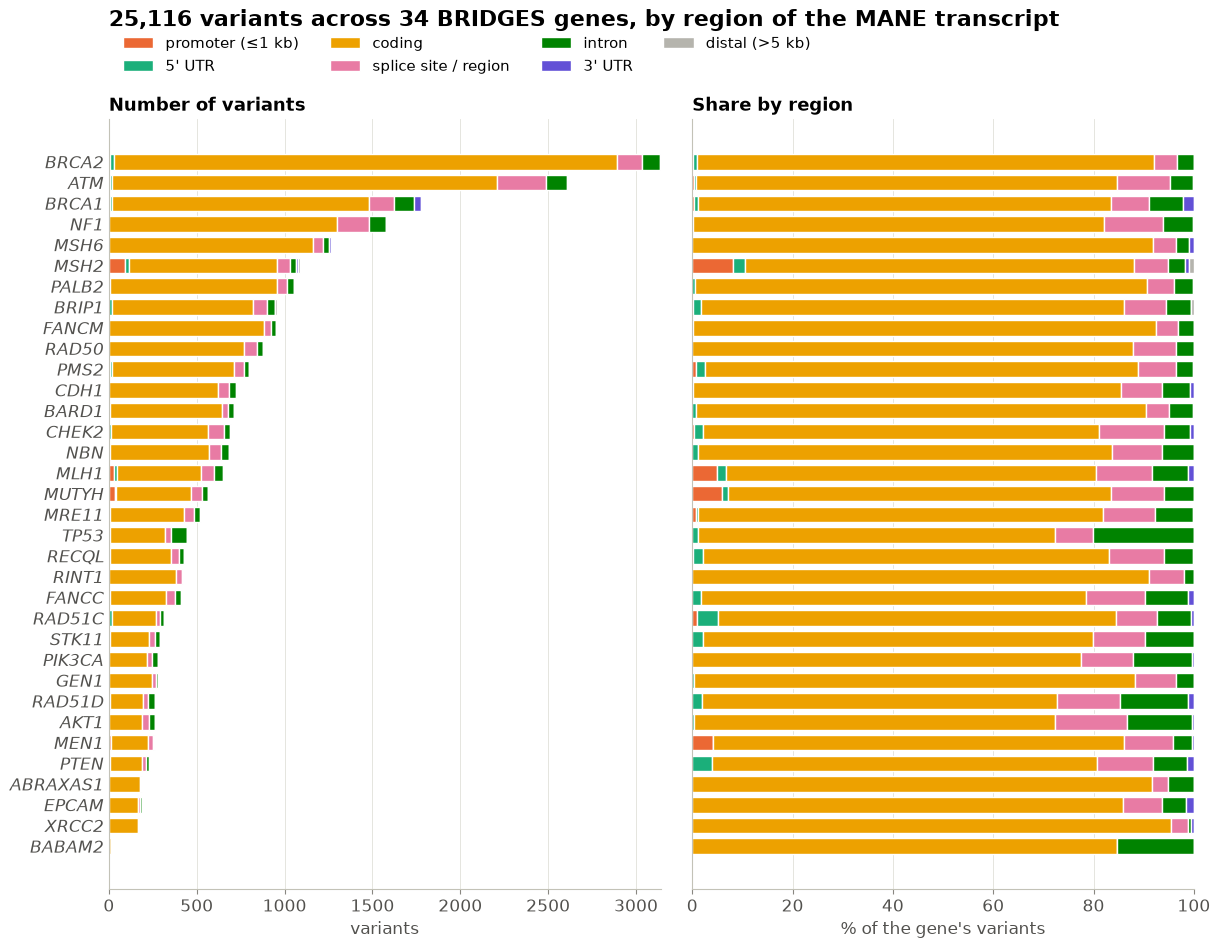

In [7]:
fig, (ax, ax_pct) = plt.subplots(
    1, 2, figsize=(14, 10), sharey=True, gridspec_kw={'width_ratios': [1.1, 1], 'wspace': 0.06}
)
y = np.arange(len(by_gene))[::-1]
for a, data in [(ax, by_gene), (ax_pct, by_gene.div(by_gene.sum(axis=1), axis=0) * 100)]:
    left = np.zeros(len(data))
    for region in USED:
        color = REGIONS[region]
        a.barh(y, data[region], left=left, color=color, height=0.75, label=region,
               edgecolor='white', lw=1)
        left += data[region].values
    a.grid(axis='x', color=GRID, lw=0.6)
    a.set_axisbelow(True)
    a.tick_params(axis='y', length=0)
ax.set_yticks(y, by_gene.index, style='italic')
ax.set_xlabel('variants')
ax_pct.set_xlabel('% of the gene\'s variants')
ax_pct.set_xlim(0, 100)
ax.set_title('Number of variants')
ax_pct.set_title('Share by region')
ax.legend(ncols=4, frameon=False, loc='lower left', bbox_to_anchor=(0, 1.04), fontsize=11)
fig.suptitle(f'{len(ann):,} variants across {len(by_gene)} BRIDGES genes, by region of the MANE transcript',
             x=0.125, ha='left', y=0.99)
save(fig, 'variants_per_gene_by_region')

## 5. Where are the variants? Coding vs non-coding

In [8]:
overall = ann.region.value_counts().reindex(USED).to_frame('variants')
overall['%'] = (100 * overall.variants / len(ann)).round(1)
display(overall)
n_coding = overall.loc['coding', 'variants']
print(f'coding: {n_coding:,} ({n_coding / len(ann):.1%});  non-coding: {len(ann) - n_coding:,} '
      f'({1 - n_coding / len(ann):.1%})')
pd.crosstab(ann.region, ann.type).reindex(USED)

,variants,%
region,,
promoter (≤1 kb),208,0.8
5' UTR,207,0.8
coding,21208,84.4
splice site / region,2039,8.1
intron,1327,5.3
3' UTR,111,0.4
distal (>5 kb),16,0.1


coding: 21,208 (84.4%);  non-coding: 3,908 (15.6%)


type,MNV / complex,SNV,deletion,insertion
region,,,,
promoter (≤1 kb),0,199,7,2
5' UTR,0,198,5,4
coding,62,19878,968,300
splice site / region,7,1841,145,46
intron,5,1163,110,49
3' UTR,0,100,7,4
distal (>5 kb),0,16,0,0


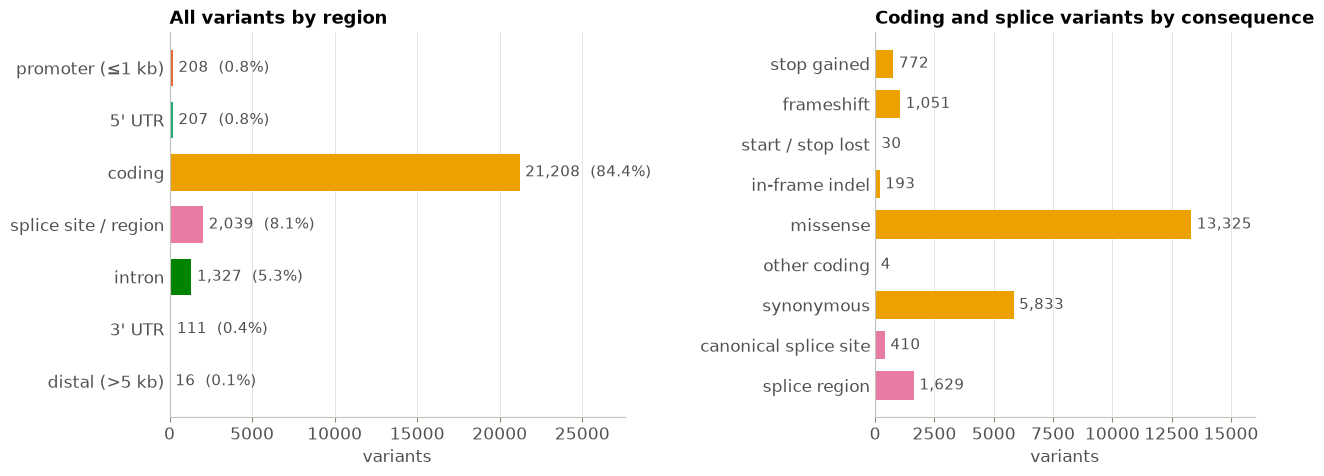

In [9]:
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1], 'wspace': 0.6})
ax.barh(overall.index[::-1], overall.variants[::-1], color=[REGIONS[r] for r in overall.index[::-1]], height=0.7)
ax.bar_label(ax.containers[0], labels=[f'{n:,}  ({p}%)' for n, p in zip(overall.variants[::-1], overall['%'][::-1])],
             padding=4, fontsize=11, color=SECONDARY)
ax.set_title('All variants by region')
ax.set_xlabel('variants')
ax.set_xlim(0, overall.variants.max() * 1.3)

detail = (ann[ann.detail.notna() & ann.detail.isin(CODING_ORDER + ['canonical splice site', 'splice region'])]
          .detail.value_counts().reindex(CODING_ORDER + ['canonical splice site', 'splice region']).fillna(0))
colors = [REGIONS['coding']] * len(CODING_ORDER) + [REGIONS['splice site / region']] * 2
ax2.barh(detail.index[::-1], detail[::-1], color=colors[::-1], height=0.7)
ax2.bar_label(ax2.containers[0], labels=[f'{int(n):,}' for n in detail[::-1]], padding=4, fontsize=11,
              color=SECONDARY)
ax2.set_title('Coding and splice variants by consequence')
ax2.set_xlabel('variants')
ax2.set_xlim(0, detail.max() * 1.2)
for a in (ax, ax2):
    a.grid(axis='x', color=GRID, lw=0.6)
    a.set_axisbelow(True)
    a.tick_params(axis='y', length=0)
save(fig, 'variants_by_region_and_consequence')

### How deep into introns?

Distance from each intronic variant to the nearest MANE exon. A capture design targeting exons would put
most intronic variants within a few hundred bp of an exon; whole-gene sequencing spreads them evenly.

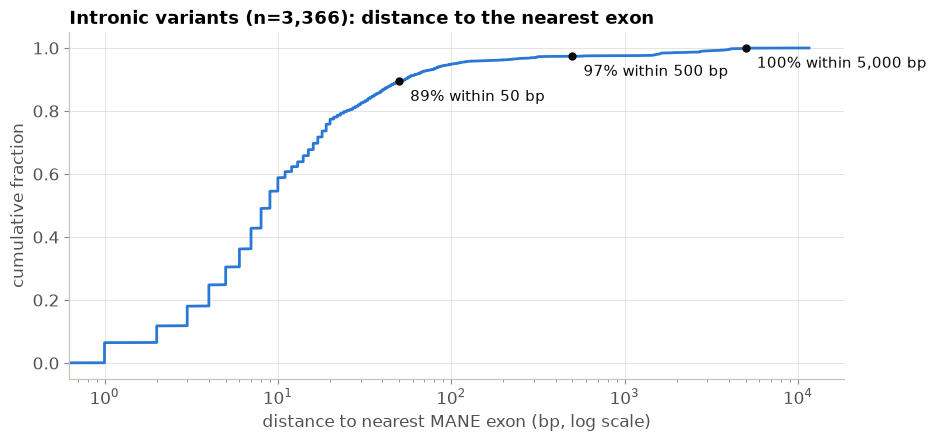

In [10]:
exons = gtf[(gtf.Feature == 'exon') & gtf.transcript_id.isin(MANE.transcript_id)]
exons = exons.assign(gene=exons.gene_name)[['gene', 'Start', 'End']]


def exon_distance(df):
    ex = exons[exons.gene == df.name]
    starts, ends = ex.Start.values + 1, ex.End.values
    p = df.pos.values[:, None]
    return pd.Series(np.minimum(np.abs(p - starts), np.abs(p - ends)).min(axis=1), index=df.index)


intronic = ann[ann.region.isin(['intron', 'splice site / region'])]
ann.loc[intronic.index, 'exon_distance'] = intronic.groupby('gene', group_keys=False).apply(exon_distance)
d = np.sort(ann.exon_distance.dropna().values)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(d, np.arange(1, len(d) + 1) / len(d), color=BLUE, lw=2)
ax.set_xscale('log')
ax.set_xlabel('distance to nearest MANE exon (bp, log scale)')
ax.set_ylabel('cumulative fraction')
ax.grid(color=GRID, lw=0.6)
ax.set_axisbelow(True)
for x in (50, 500, 5000):
    frac = (d <= x).mean()
    ax.annotate(f'{frac:.0%} within {x:,} bp', (x, frac), xytext=(8, -14), textcoords='offset points',
                fontsize=11, color=INK)
    ax.plot(x, frac, 'o', color=INK, ms=5)
ax.set_title(f'Intronic variants (n={len(d):,}): distance to the nearest exon')
save(fig, 'intronic_distance_to_exon')

### Overlap with the earlier Seqweaver variant set

In [11]:
seqweaver = pd.read_csv(ROOT / 'data/eirik/Seqweaver_bridges__breast.csv', usecols=[0]).iloc[:, 0]
ann['in_seqweaver_set'] = ann.VariantID.isin(seqweaver)
print(f'{ann.in_seqweaver_set.sum():,} of {len(ann):,} variants are also in the Seqweaver set '
      f'({seqweaver.nunique():,} variants); {len(ann) - ann.in_seqweaver_set.sum():,} are new')
pd.crosstab(ann.region, ann.in_seqweaver_set).reindex(USED).rename(
    columns={True: 'also in Seqweaver set', False: 'new'})

10,066 of 25,116 variants are also in the Seqweaver set (10,066 variants); 15,050 are new


in_seqweaver_set,new,also in Seqweaver set
region,,
promoter (≤1 kb),9,199
5' UTR,16,191
coding,12892,8316
splice site / region,1263,776
intron,781,546
3' UTR,73,38
distal (>5 kb),16,0


### Summary

- All 34 BRIDGES genes are covered, but very unevenly: BRCA2, ATM and BRCA1 have 1,800-3,100 variants each,
  BABAM2 only 13.
- The set is overwhelmingly coding (~84%: mostly missense and synonymous, ~1,800 stop-gained or frameshift).
- The non-coding part is almost entirely exon-adjacent: splice regions and introns close to exons
  (~89% of intronic variants are within 50 bp of an exon), plus small numbers in UTRs and promoters
  (MSH2, MLH1, MUTYH, MEN1). There are no variants 1-5 kb up- or downstream, and only 16 lie more than 5 kb from a gene.
  This looks like an exon-targeted capture, not whole-gene sequencing.

## 6. Genome tracks per gene

For each gene: variant density, one row of ticks per region class, and the gene models (MANE transcript of
the BRIDGES gene in black; other protein-coding genes in the window in grey). Tall boxes are CDS, short
boxes UTR exons. Coordinates are hg38. Saved to `new_bridges34_figures/tracks/`.

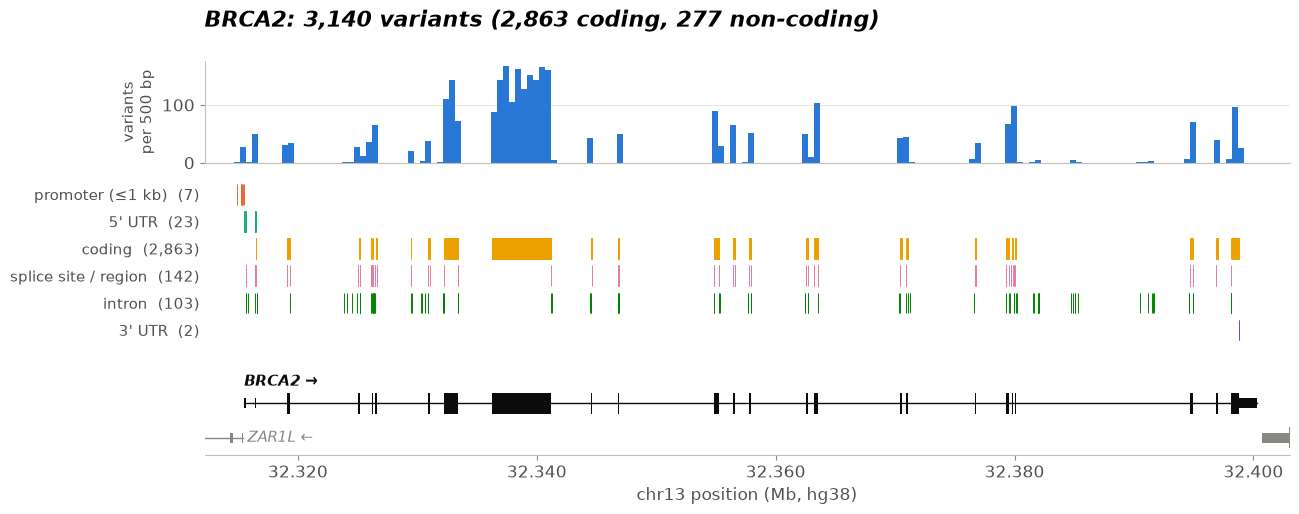

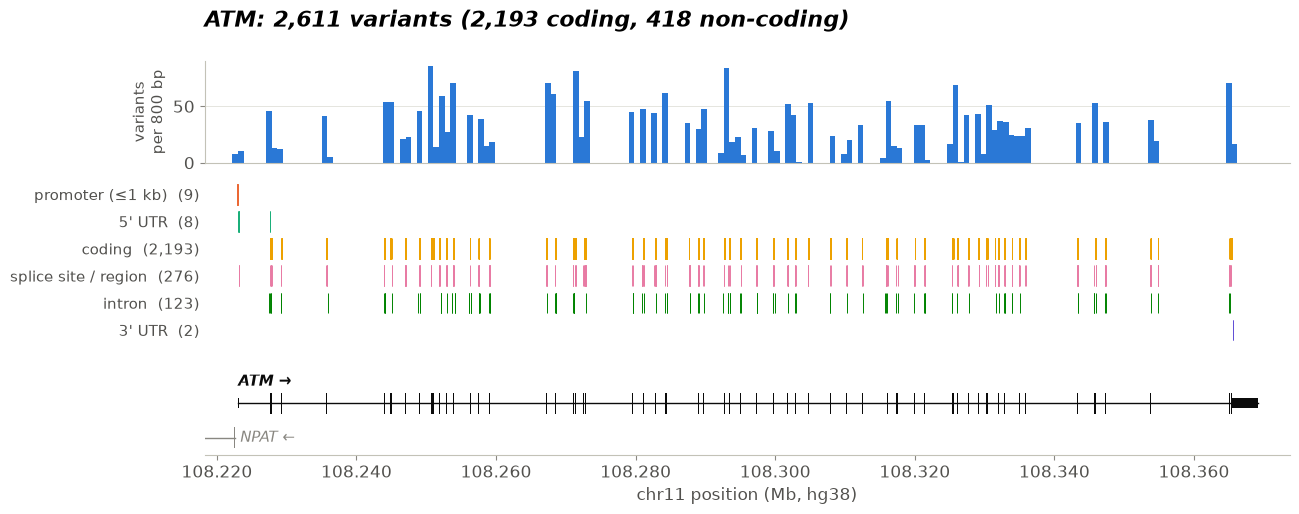

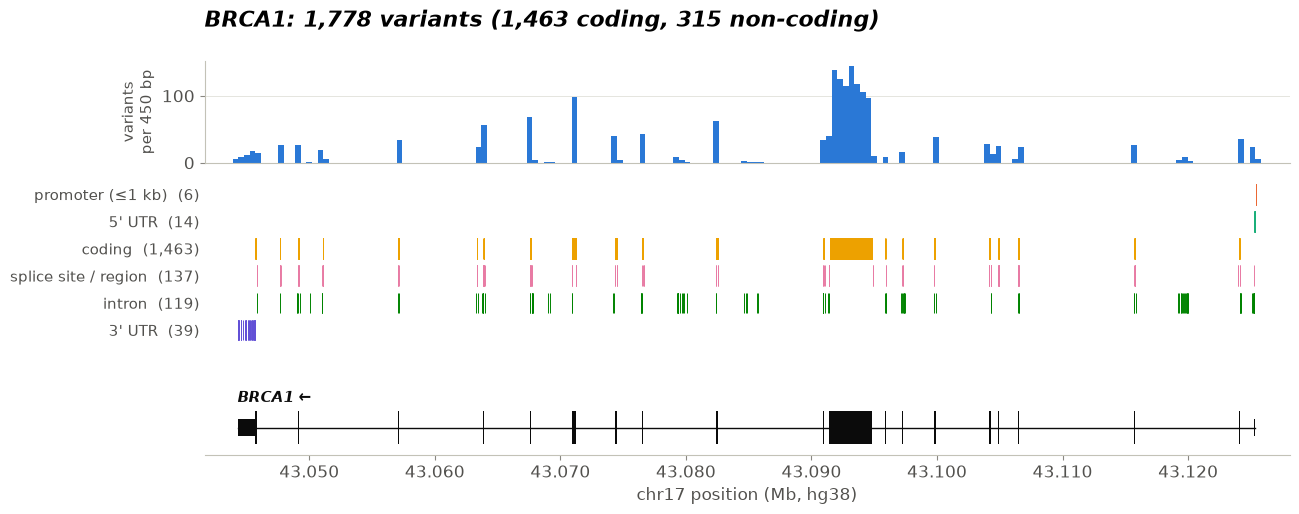

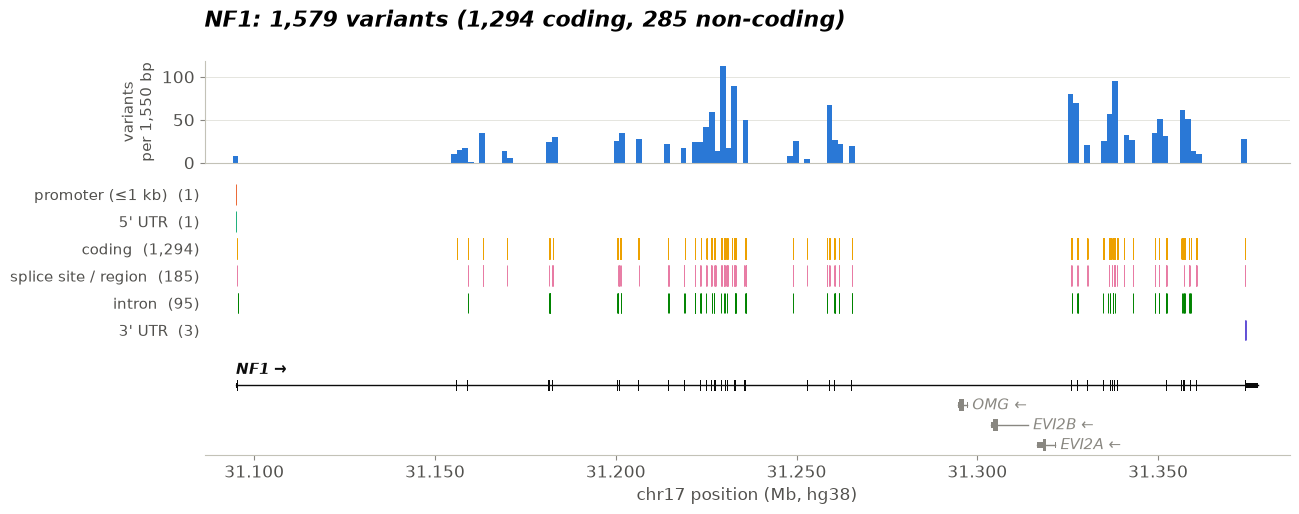

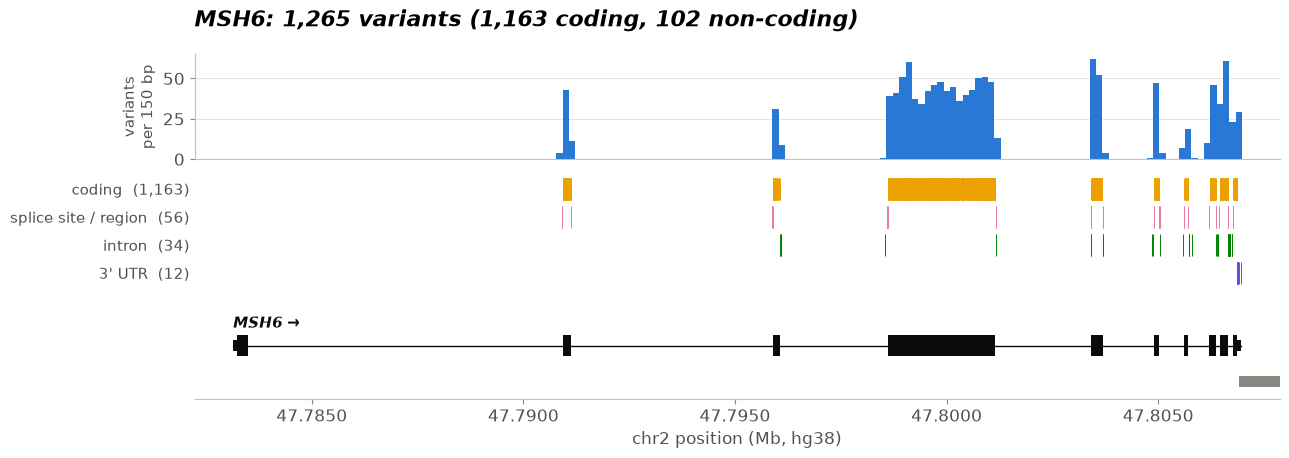

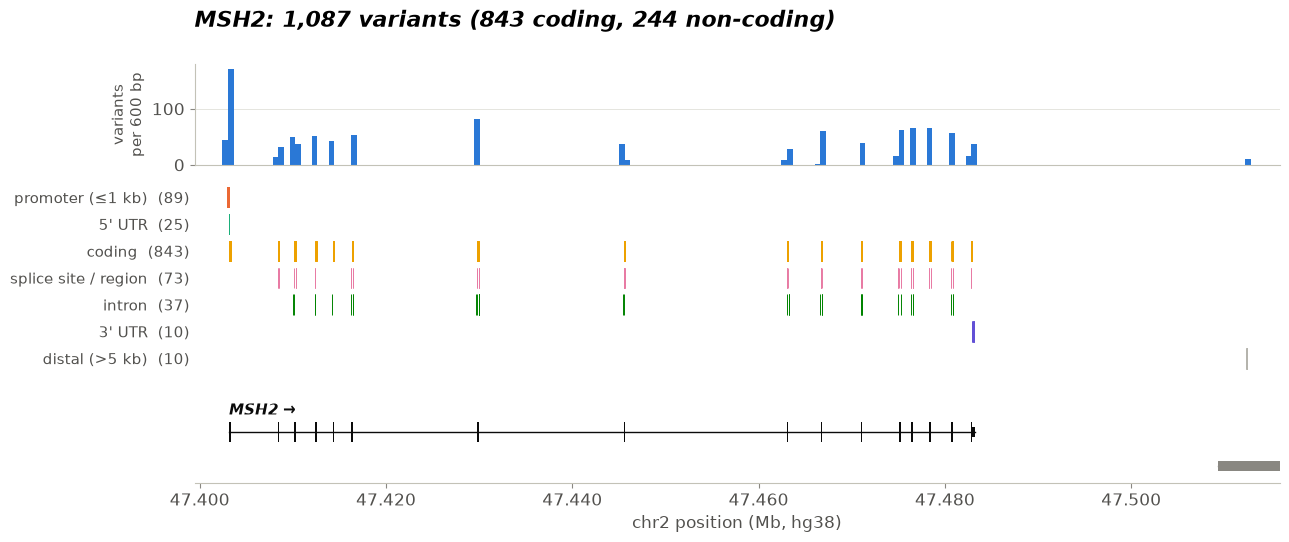

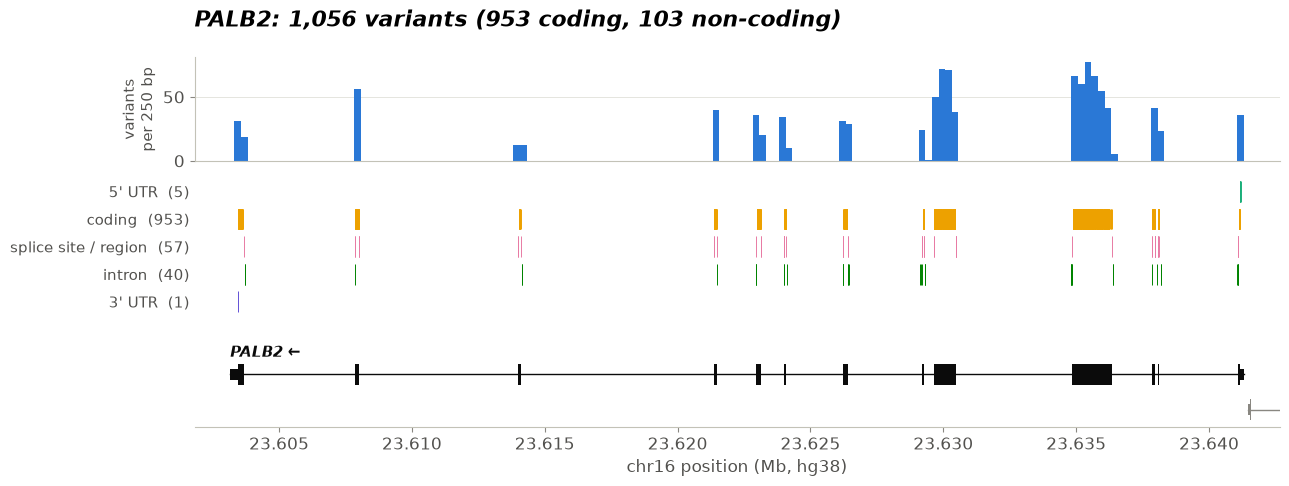

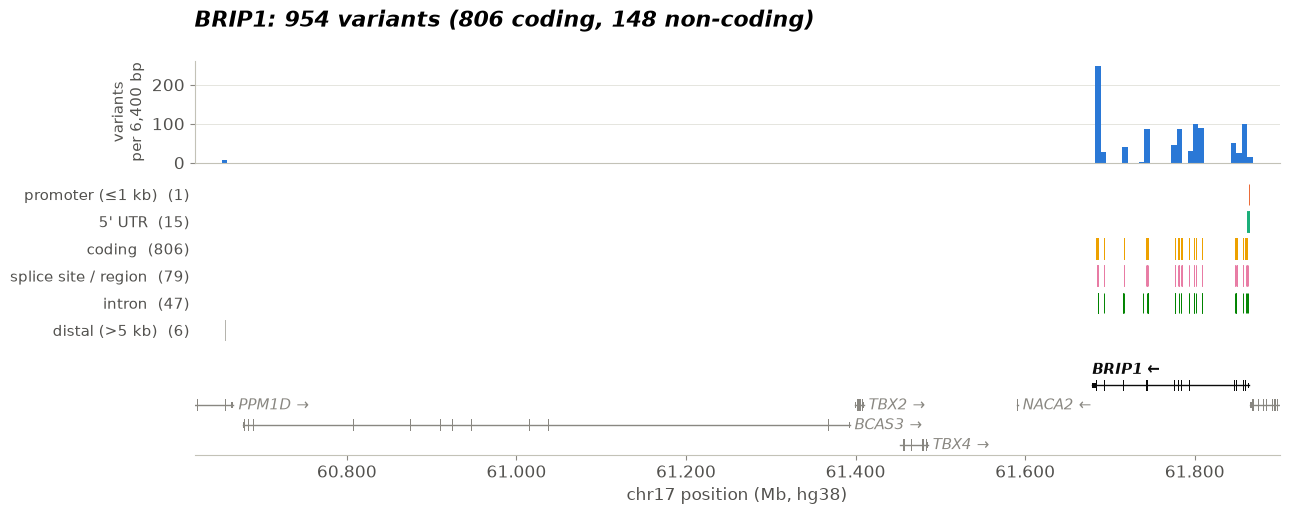

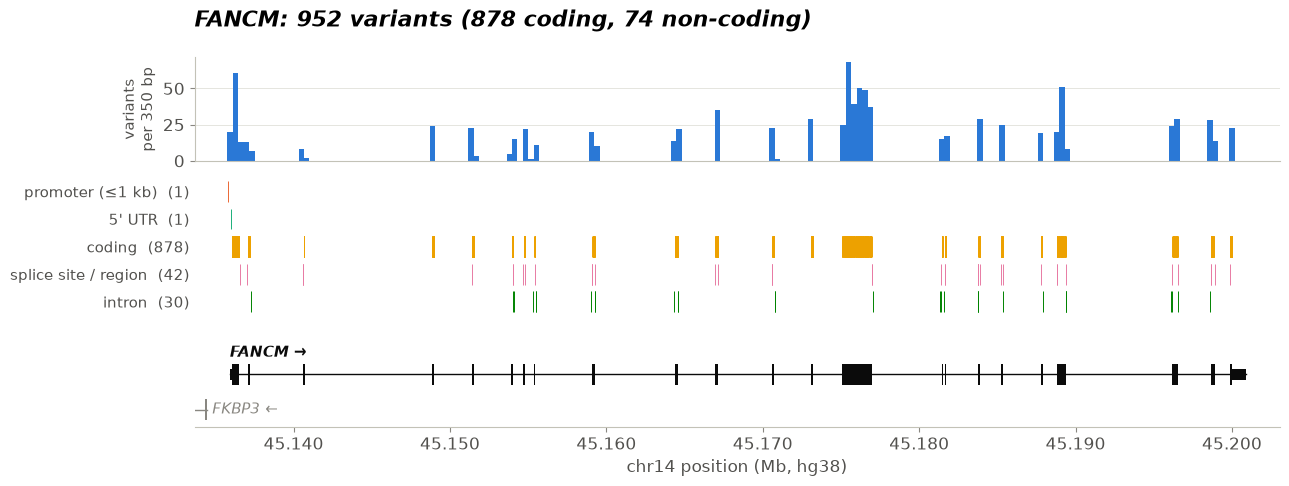

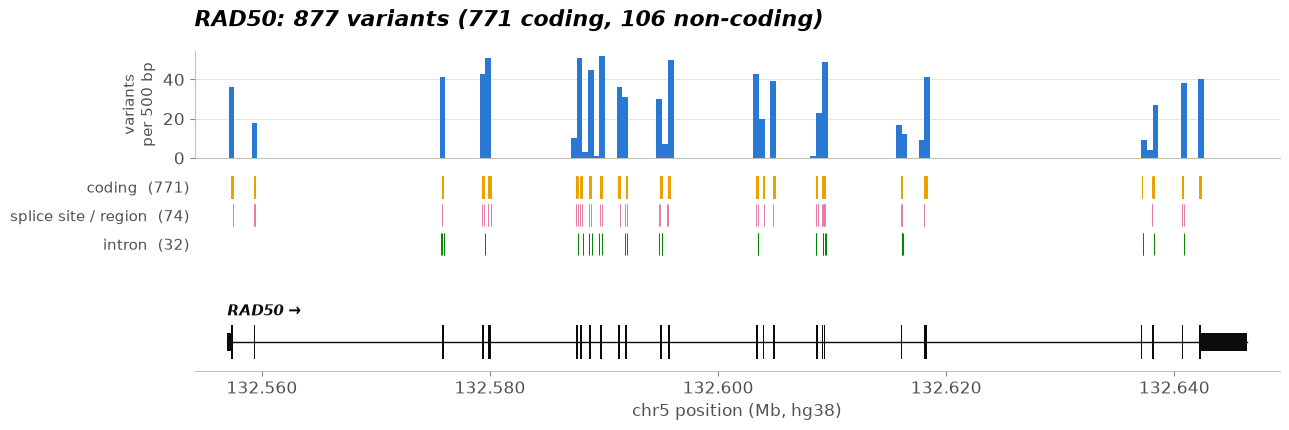

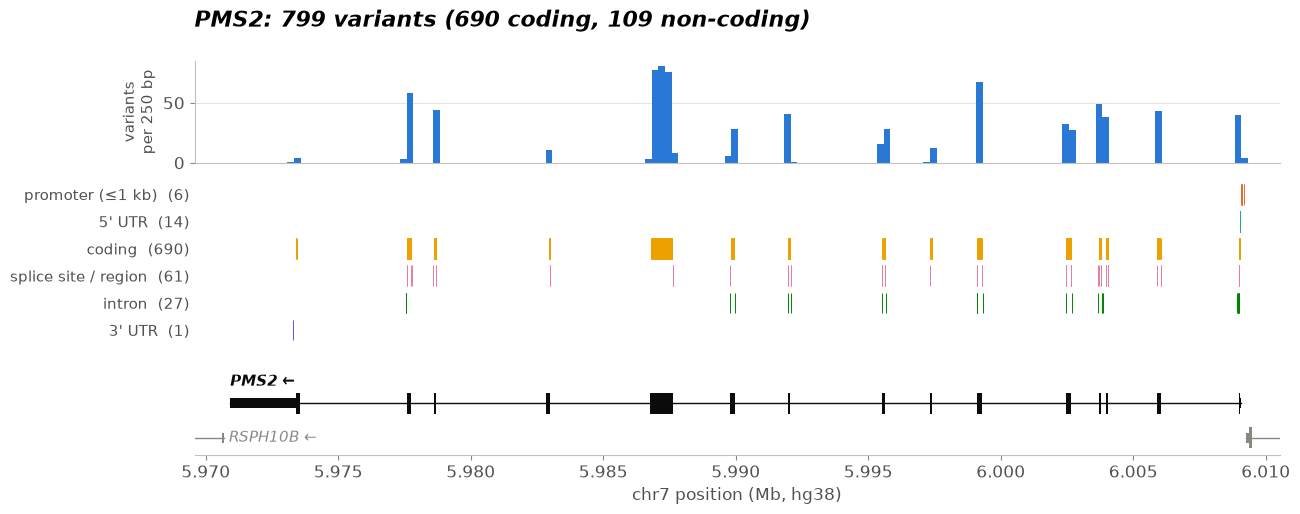

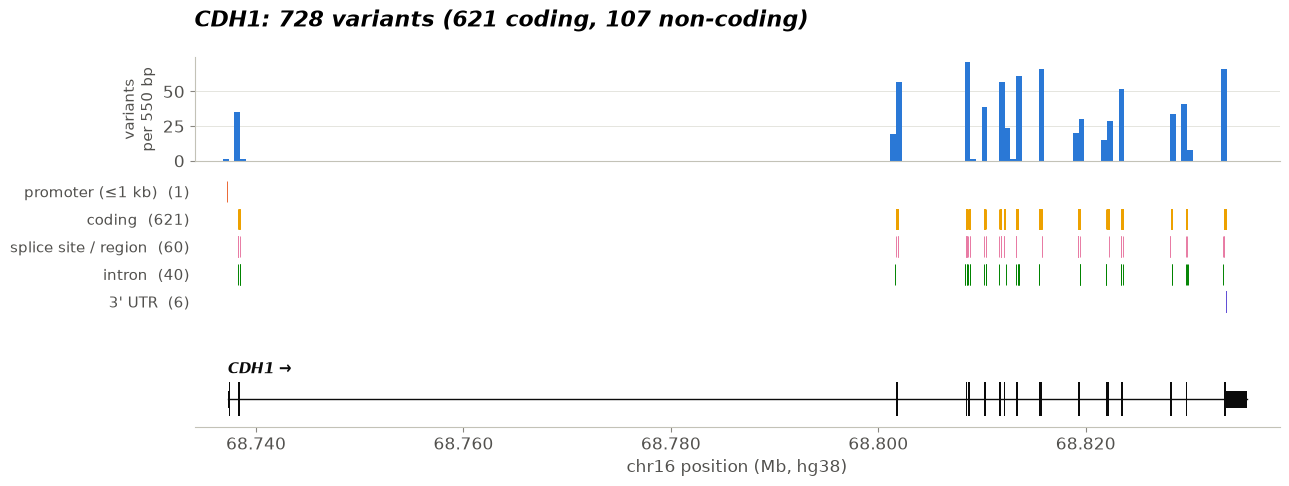

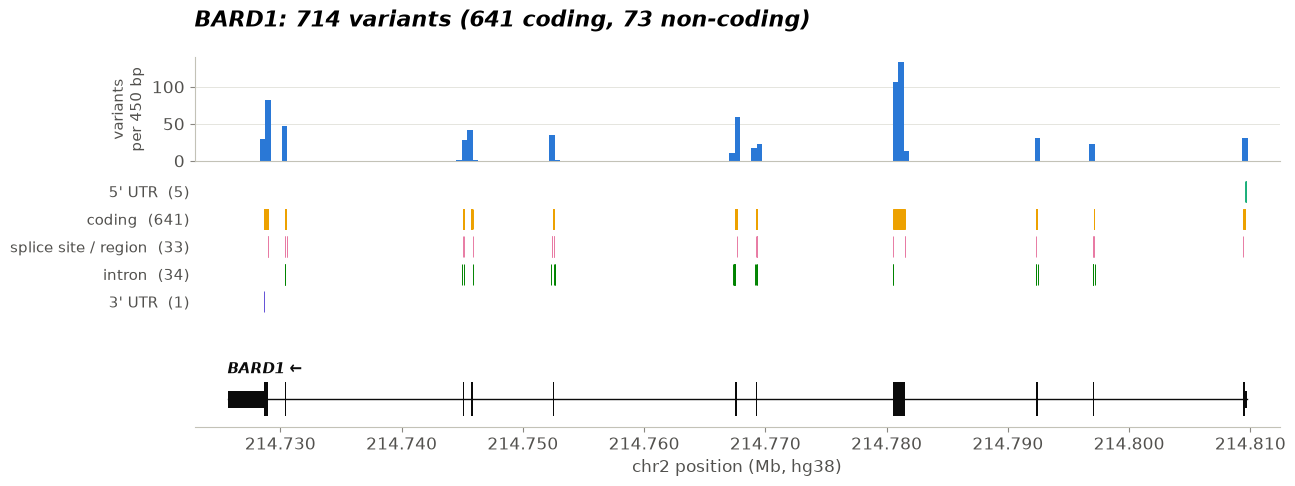

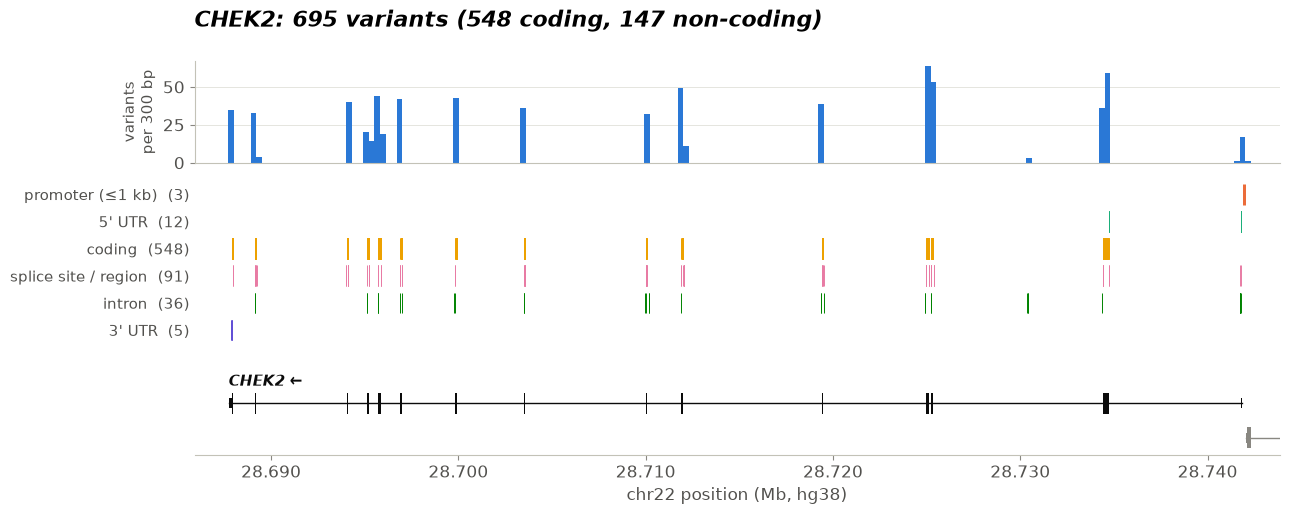

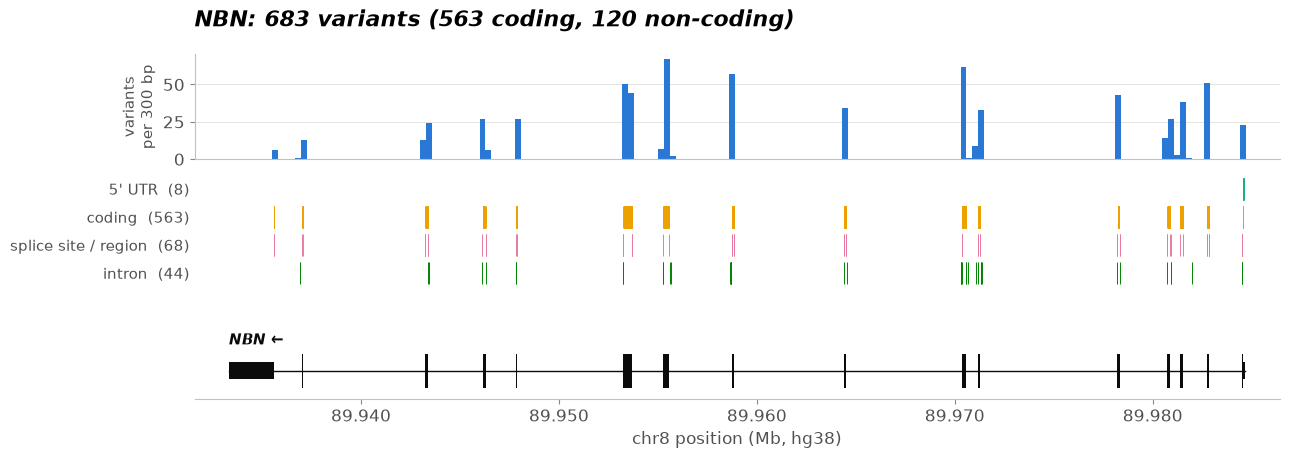

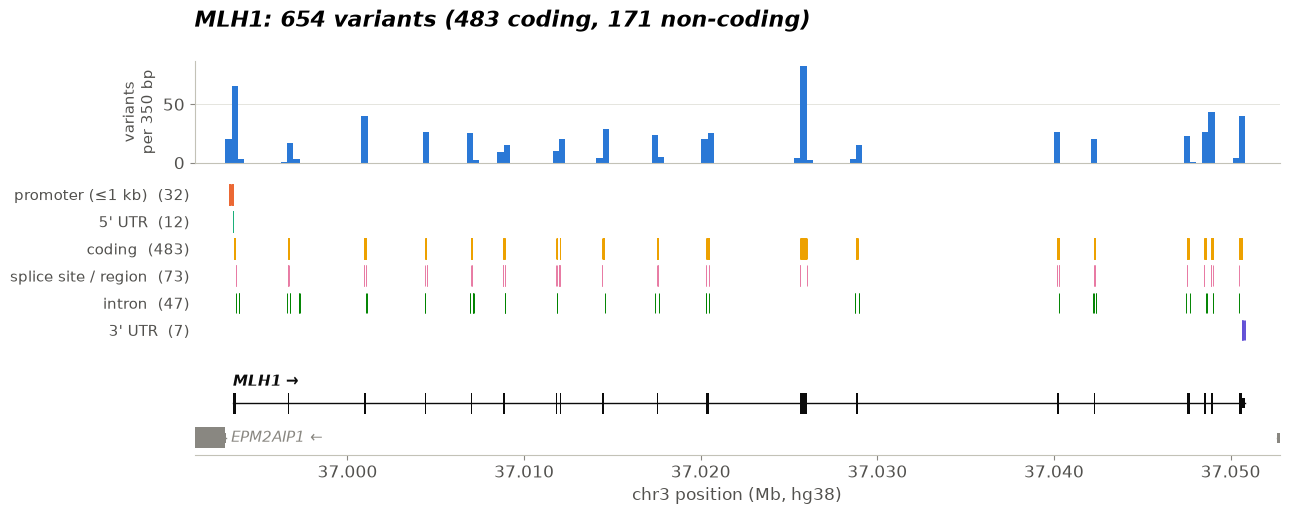

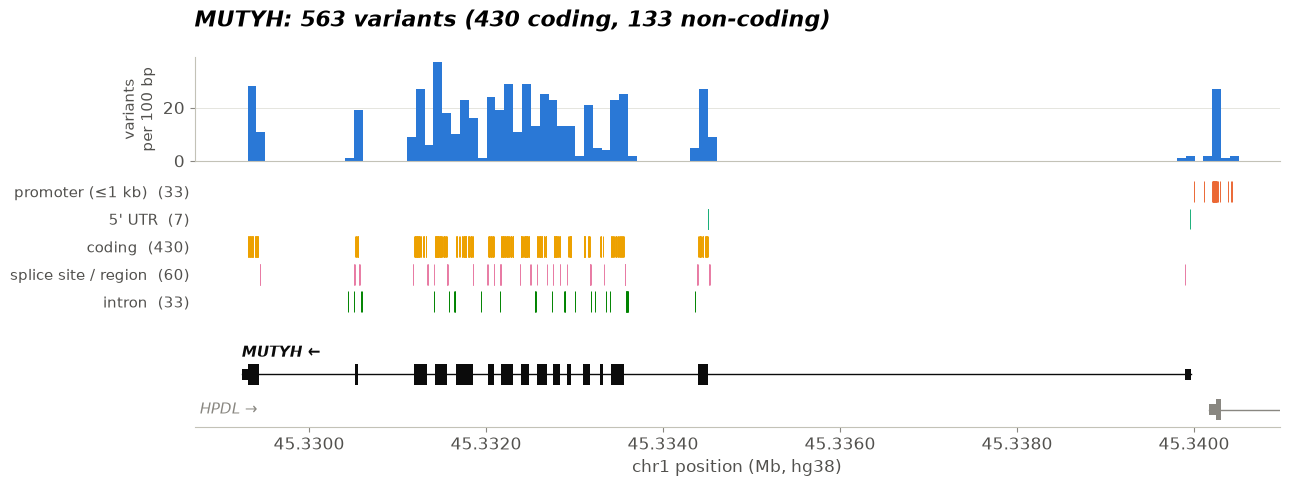

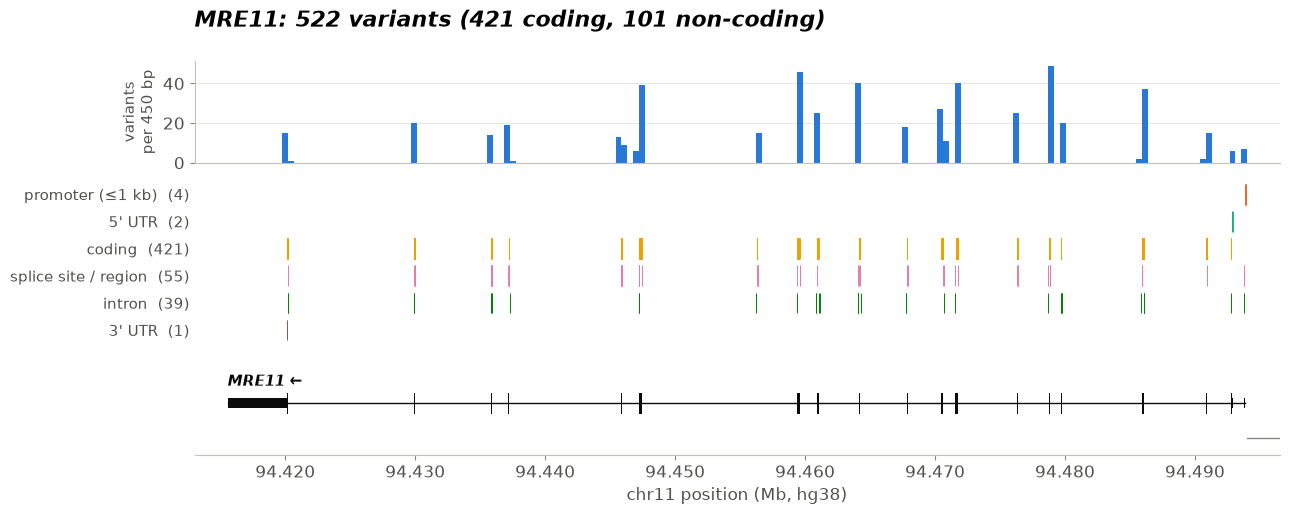

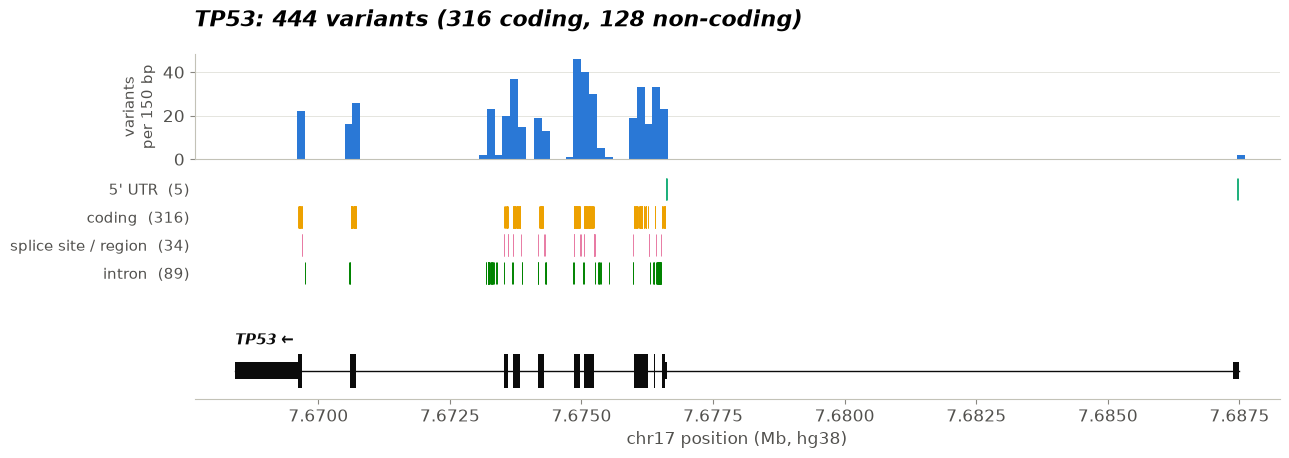

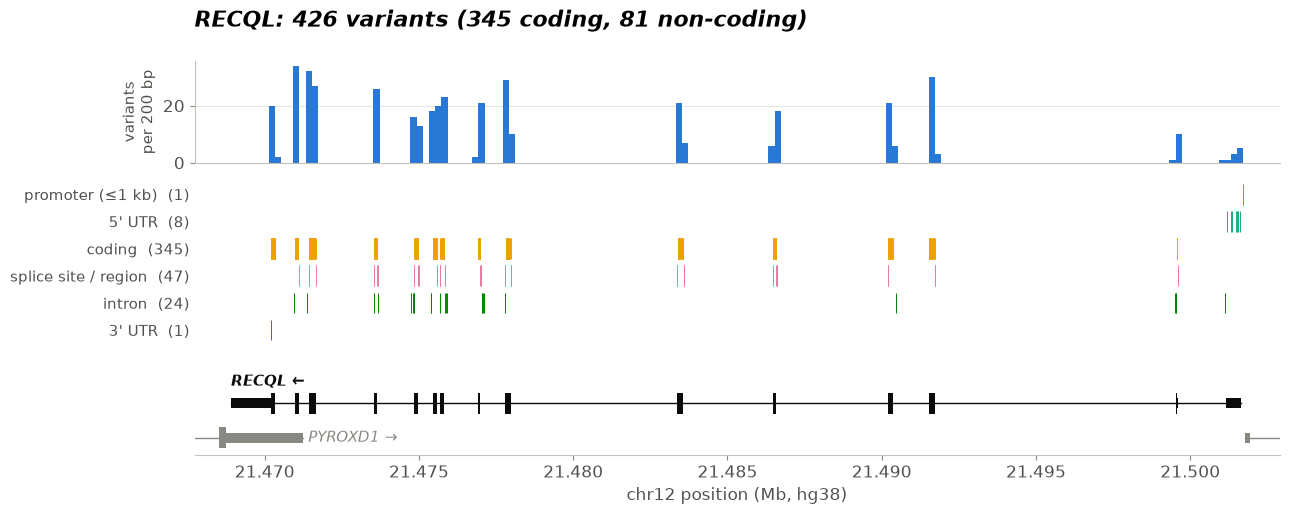

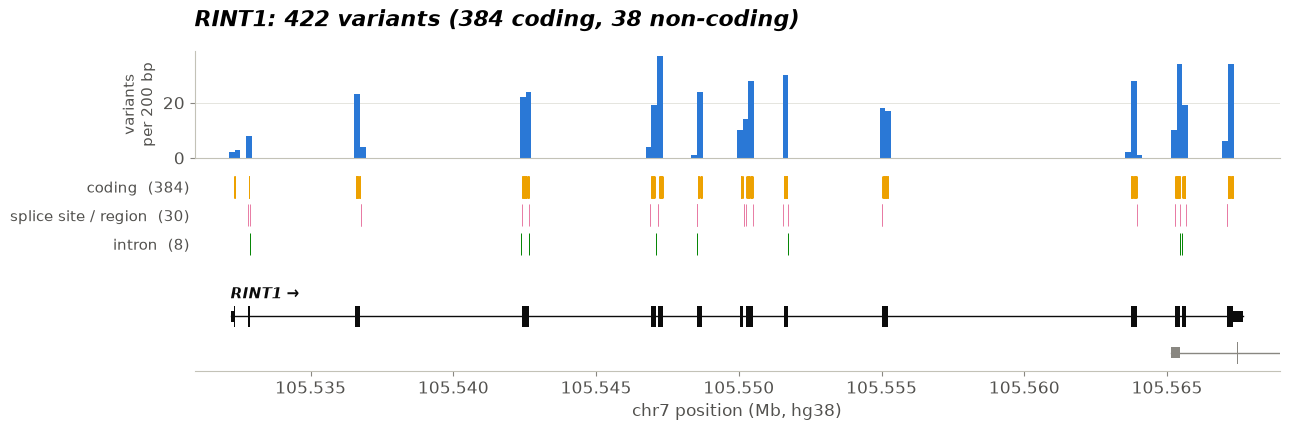

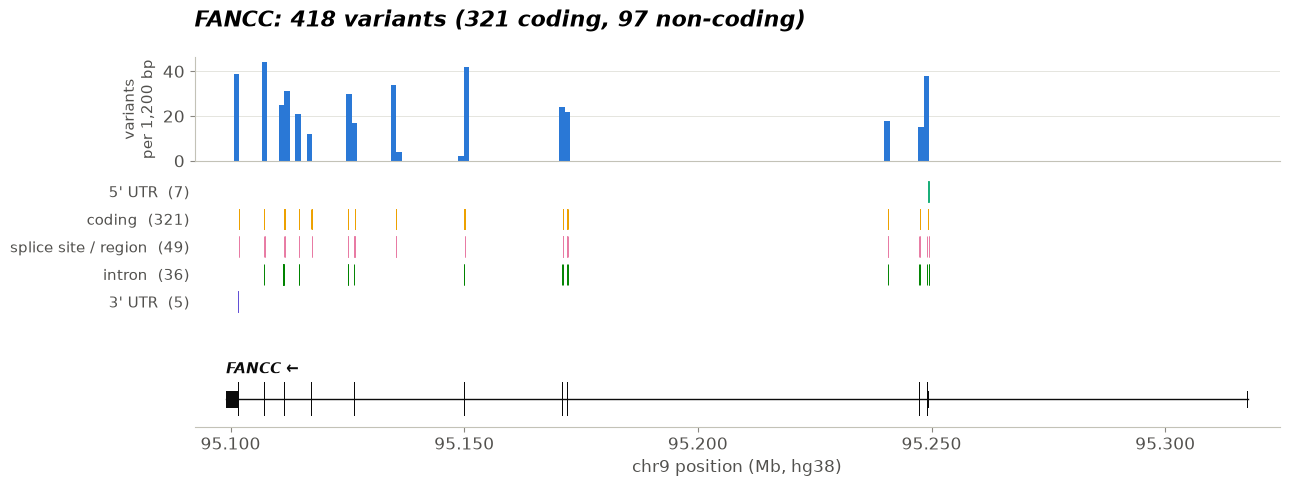

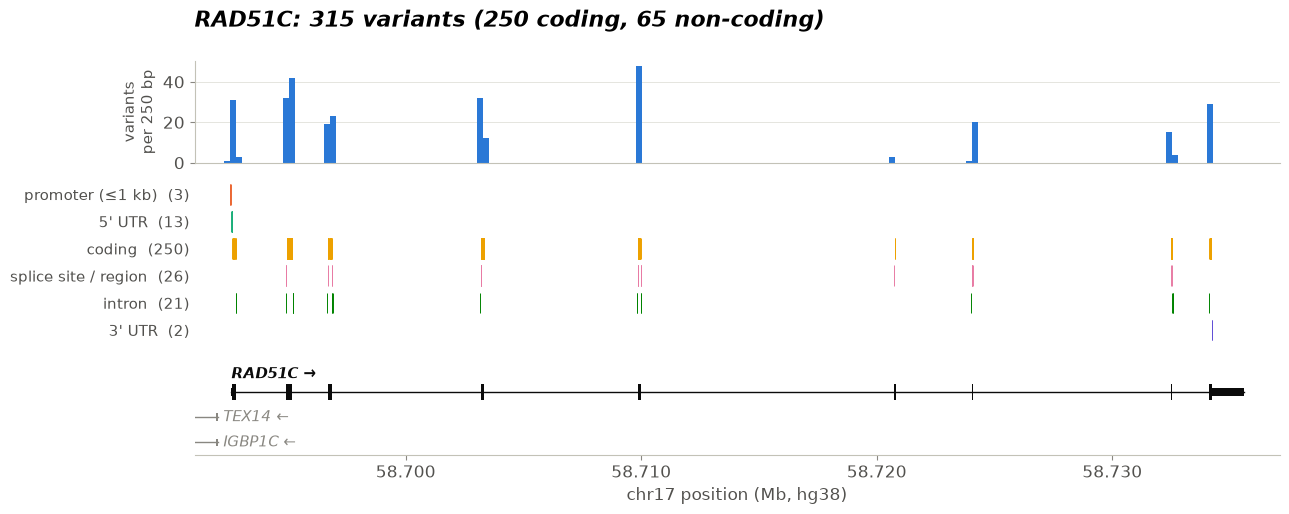

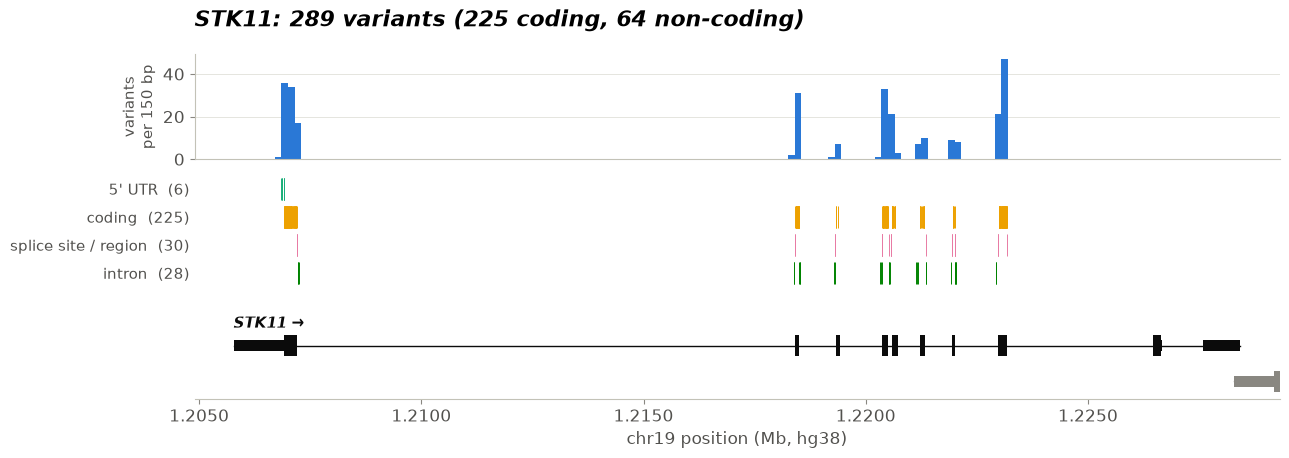

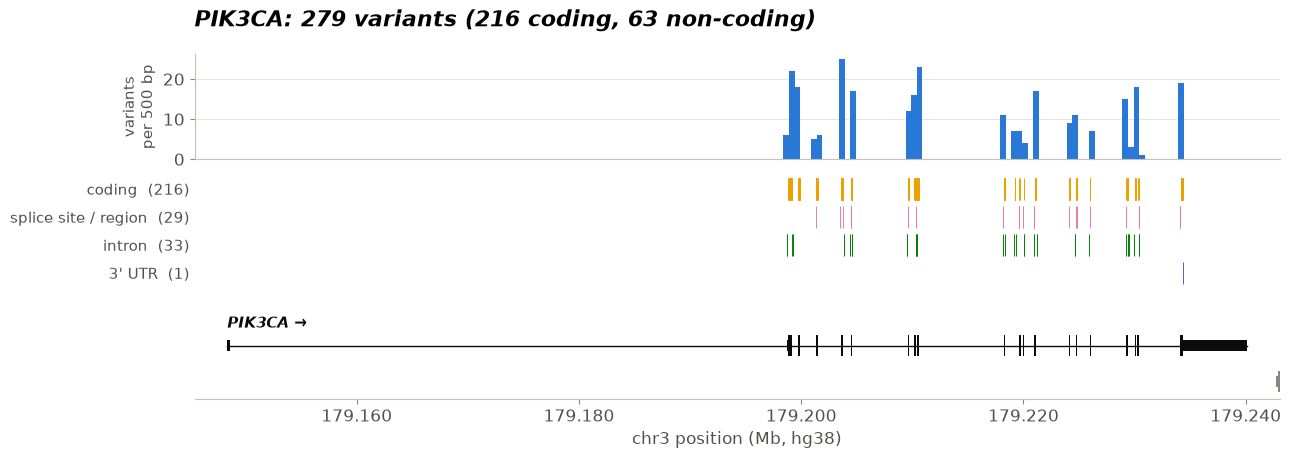

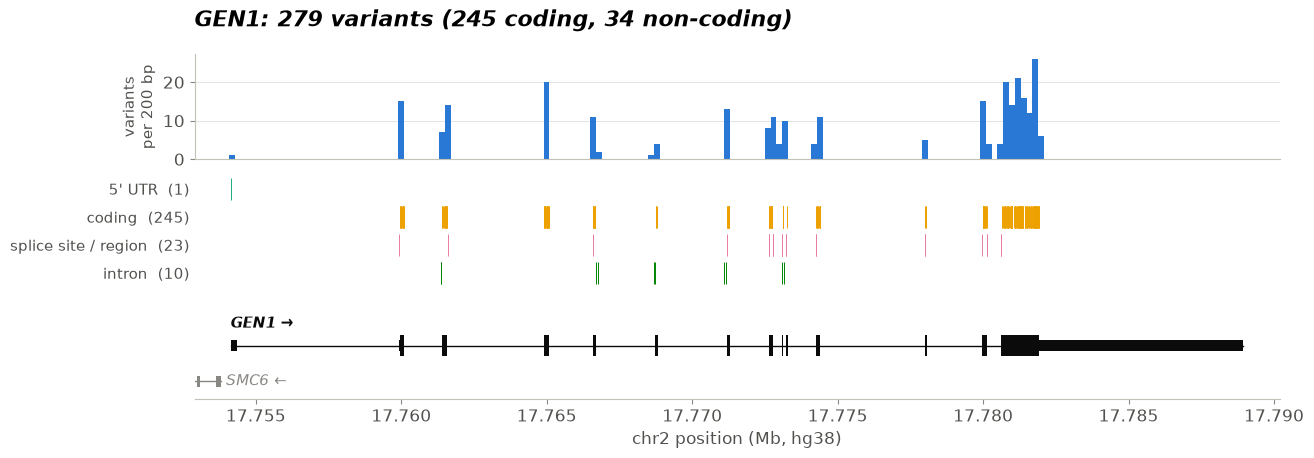

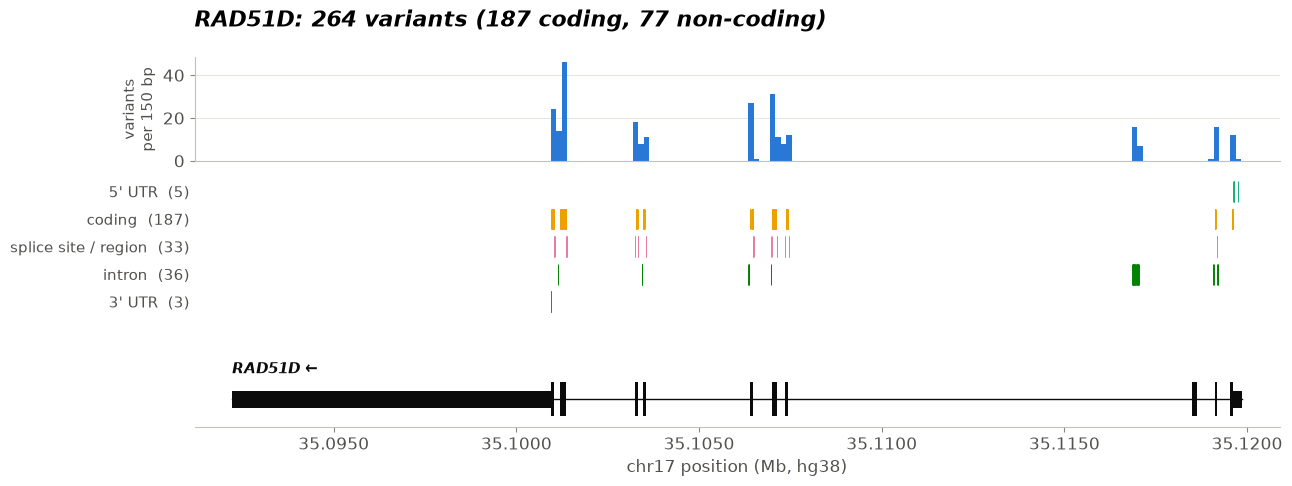

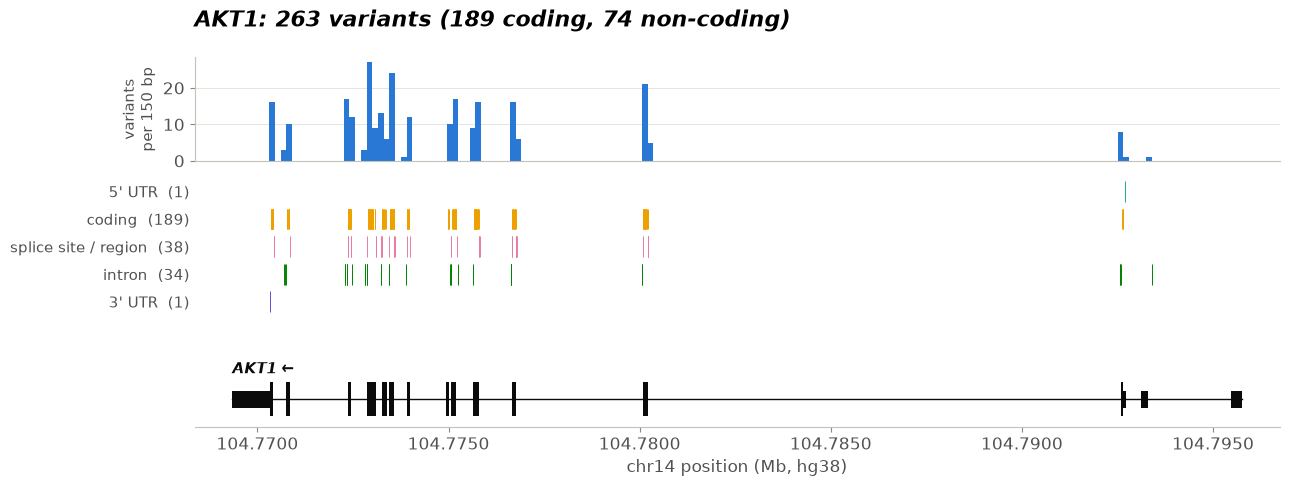

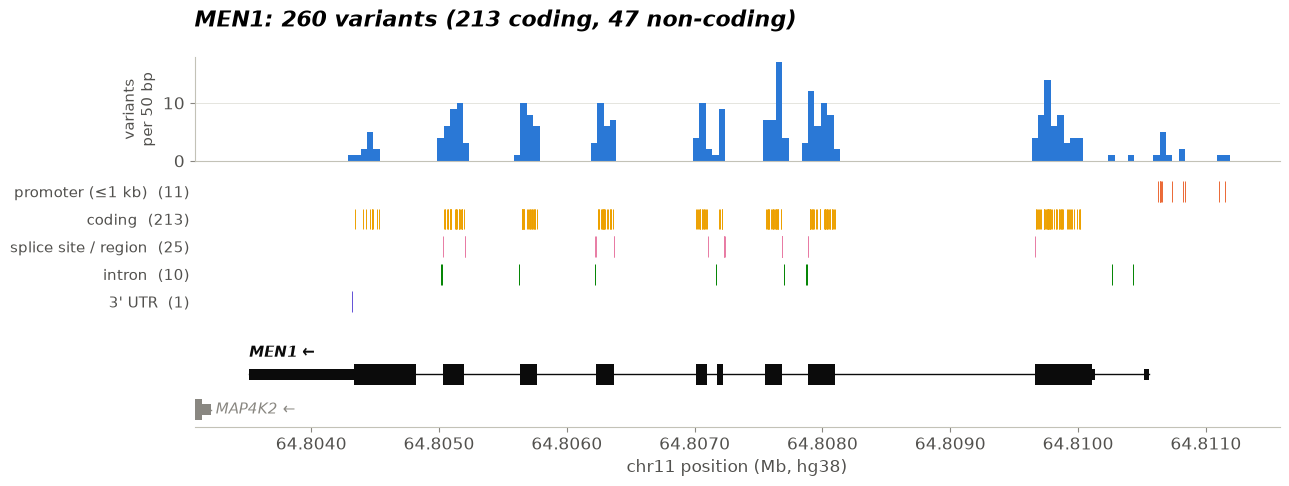

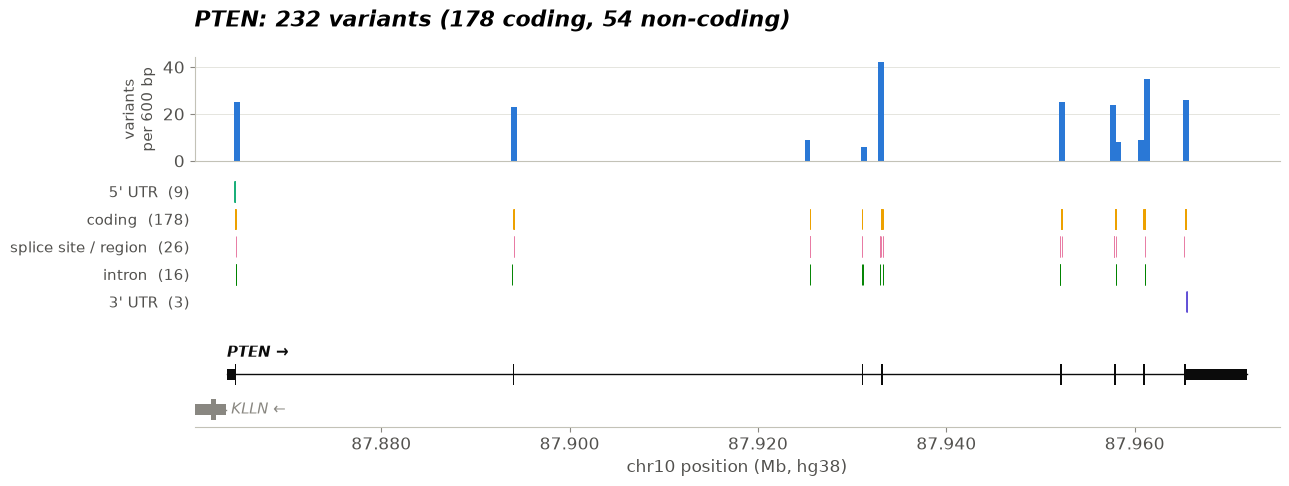

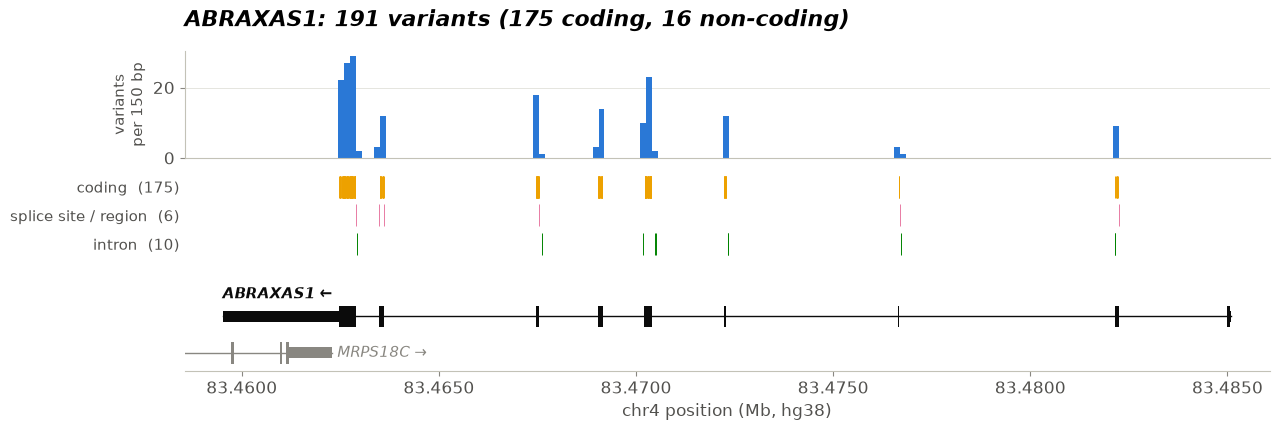

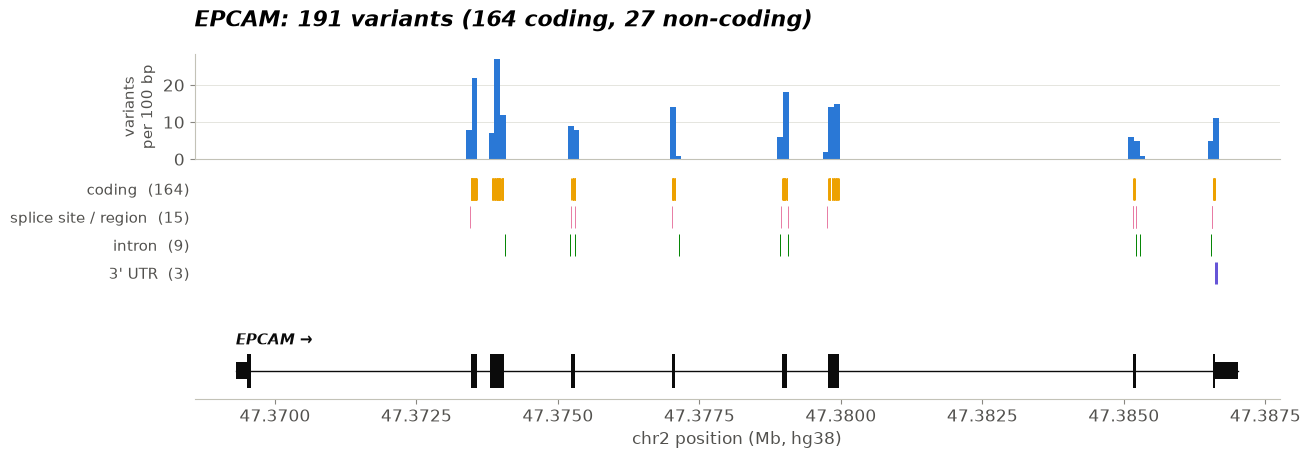

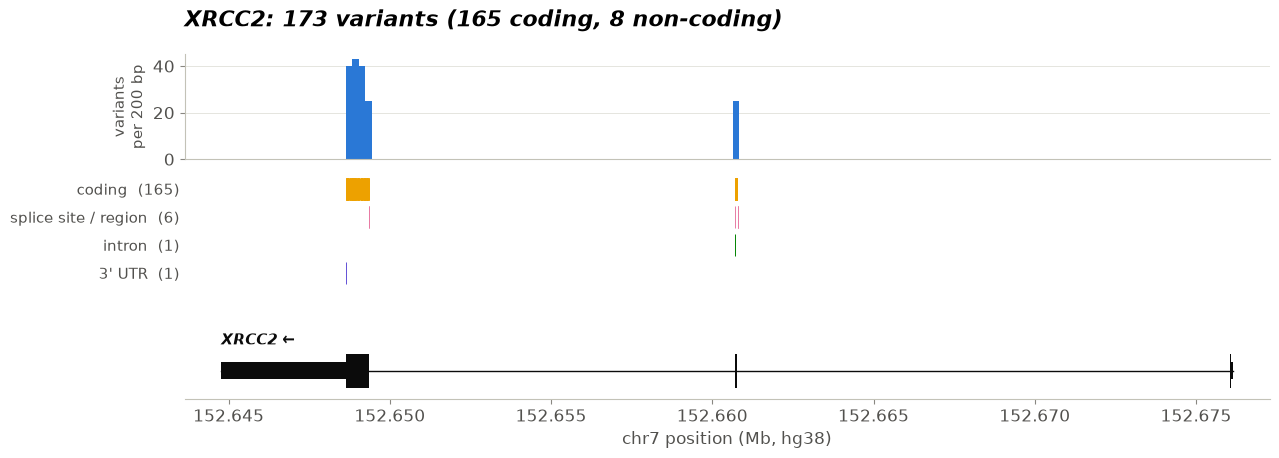

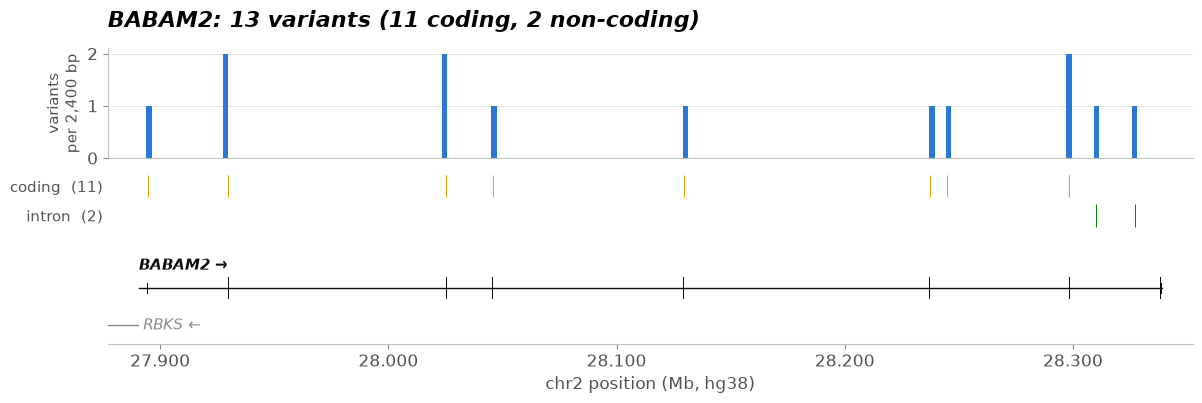

In [12]:
(FIGDIR / 'tracks').mkdir(exist_ok=True)


def draw_gene_models(ax, chrom, start, end, target):
    """MANE (or longest) transcript of each protein-coding gene in the window, packed into rows."""
    genes = gtf[(gtf.Feature == 'gene') & (gtf.Chromosome == chrom) & (gtf.End > start)
                & (gtf.Start < end) & (gtf.gene_type == 'protein_coding')
                & ~gtf.gene_name.str.startswith('ENSG')]
    genes = pd.concat([genes[genes.gene_name == target], genes[genes.gene_name != target]])
    row_end, min_width = [], (end - start) / 1500
    for g in genes.itertuples():
        tx = gtf[(gtf.gene_id == g.gene_id) & (gtf.Feature == 'transcript')]
        is_mane = tx.tag.str.contains('MANE_Select', na=False)
        tx = tx[is_mane].iloc[0] if is_mane.any() else tx.loc[(tx.End - tx.Start).idxmax()]
        lo, hi = max(tx.Start, start), min(tx.End, end)
        if lo >= hi:  # gene overlaps the window but its transcript does not
            continue
        row = 0 if g.gene_name == target else next(
            (i for i, e in enumerate(row_end) if i > 0 and lo > e), max(len(row_end), 1))
        row_end += [-np.inf] * (row + 1 - len(row_end))
        row_end[row] = hi + (end - start) * 0.12
        y, color = -row, INK if g.gene_name == target else MUTED
        ax.plot([lo, hi], [y, y], color=color, lw=1)
        parts = gtf[gtf.transcript_id == tx.transcript_id]
        for feature, h in [('exon', 0.15), ('CDS', 0.3)]:
            for f in parts[parts.Feature == feature].itertuples():
                a, b = max(f.Start, start), min(f.End, end)
                if a < b:  # at least ~1 px wide, so small exons of long genes stay visible
                    w = max(b - a, min_width)
                    ax.add_patch(plt.Rectangle(((a + b - w) / 2, y - h), w, 2 * h, color=color, lw=0))
        arrow = '←' if tx.Strand == '-' else '→'
        label = dict(fontsize=11, color=color, style='italic', clip_on=True)
        if g.gene_name == target:  # above its own row, which nothing else shares
            ax.text(lo, y + 0.4, f'{g.gene_name} {arrow}', ha='left', va='bottom', weight='bold', **label)
        else:  # to the right of the gene, inside the space reserved by the packing
            ax.text(hi, y, f' {g.gene_name} {arrow}', ha='left', va='center', **label)
    ax.set_ylim(-max(len(row_end), 1) + 0.5, 1.2)
    ax.set_yticks([])
    for side in ('left', 'bottom'):
        ax.spines[side].set_visible(False)
    ax.tick_params(bottom=False)


def figure_gene_track(gene, n_bins=200):
    df = ann[ann.gene == gene]
    t = MANE.loc[gene]
    lo, hi = min(df.pos.min(), t.Start), max(df.pos.max(), t.End)
    pad = int((hi - lo) * 0.03) + 200
    start, end = lo - pad, hi + pad
    present = [r for r in REGIONS if (df.region == r).any()]

    fig, (ax_d, ax_v, ax_g) = plt.subplots(
        3, 1, figsize=(14, 3.2 + 0.32 * len(present)), sharex=True,
        gridspec_kw={'height_ratios': [1.2, 0.32 * len(present), 1.1], 'hspace': 0.15},
    )
    bin_bp = max(int(np.ceil((end - start) / n_bins / 50) * 50), 50)
    edges = np.arange(start, end + bin_bp, bin_bp)
    ax_d.hist(df.pos, bins=edges, color=BLUE, lw=0)
    ax_d.set_ylabel(f'variants\nper {bin_bp:,} bp', fontsize=11)
    ax_d.grid(axis='y', color=GRID, lw=0.6)
    ax_d.set_axisbelow(True)
    ax_d.locator_params(axis='y', nbins=3)
    ax_d.tick_params(bottom=False)

    for i, region in enumerate(present):
        pos = df.pos[df.region == region]
        ax_v.vlines(pos, -i - 0.38, -i + 0.38, color=REGIONS[region], lw=0.7)
    ax_v.set_yticks(-np.arange(len(present)),
                    [f'{r}  ({(df.region == r).sum():,})' for r in present], fontsize=11)
    ax_v.set_ylim(-len(present) + 0.5, 0.5)
    ax_v.tick_params(axis='y', length=0)
    ax_v.tick_params(bottom=False)
    ax_v.spines['left'].set_visible(False)
    ax_v.spines['bottom'].set_visible(False)

    draw_gene_models(ax_g, t.Chromosome, start, end, gene)
    ax_g.set_xlim(start, end)
    digits = 4 if end - start < 30_000 else 3
    ax_g.xaxis.set_major_formatter(lambda x, _: f'{x / 1e6:.{digits}f}')
    ax_g.tick_params(bottom=True)
    ax_g.spines['bottom'].set_visible(True)
    ax_g.set_xlabel(f'{t.Chromosome} position (Mb, hg38)')
    n_coding = (df.region == 'coding').sum()
    fig.suptitle(f'{gene}: {len(df):,} variants ({n_coding:,} coding, {len(df) - n_coding:,} non-coding)',
                 x=0.125, ha='left', y=0.98, style='italic')
    return fig


for gene in by_gene.index:
    fig = figure_gene_track(gene)
    fig.savefig(FIGDIR / 'tracks' / f'{gene}_variant_track.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 7. The Seqweaver subset: coding vs non-coding

The same statistics as section 5, restricted to the 10,066 variants that are also in the Seqweaver set
(`data/eirik/Seqweaver_bridges__breast.csv`). All of them are in the new BRIDGES set, so they reuse its
liftover, VEP annotation and region classes.

In [13]:
sw = ann[ann.in_seqweaver_set]
sw_overall = sw.region.value_counts().reindex(USED).fillna(0).astype(int).to_frame('variants')
sw_overall['%'] = (100 * sw_overall.variants / len(sw)).round(1)
sw_overall['% in full set'] = overall['%']
display(sw_overall)
n_coding = sw_overall.loc['coding', 'variants']
print(f'coding: {n_coding:,} ({n_coding / len(sw):.1%});  non-coding: {len(sw) - n_coding:,} '
      f'({1 - n_coding / len(sw):.1%})')
pd.crosstab(sw.region, sw.type).reindex(USED).fillna(0).astype(int)

,variants,%,% in full set
region,,,
promoter (≤1 kb),199,2.0,0.8
5' UTR,191,1.9,0.8
coding,8316,82.6,84.4
splice site / region,776,7.7,8.1
intron,546,5.4,5.3
3' UTR,38,0.4,0.4
distal (>5 kb),0,0.0,0.1


coding: 8,316 (82.6%);  non-coding: 1,750 (17.4%)


type,SNV
region,
promoter (≤1 kb),199
5' UTR,191
coding,8316
splice site / region,776
intron,546
3' UTR,38
distal (>5 kb),0


In [14]:
# Coding vs non-coding per gene, Seqweaver subset.
sw_by_gene = pd.crosstab(sw.gene, sw.region).reindex(columns=USED, fill_value=0)
sw_by_gene = sw_by_gene.loc[sw_by_gene.sum(axis=1).sort_values(ascending=False).index]
sw_summary = pd.DataFrame({'variants': sw_by_gene.sum(axis=1)})
sw_summary['% coding'] = (100 * sw_by_gene['coding'] / sw_summary.variants).round(1)
sw_summary['% non-coding'] = (100 - sw_summary['% coding']).round(1)
sw_summary['% coding in full set'] = summary['% coding']
print(f'{len(sw_by_gene)} of 34 BRIDGES genes have Seqweaver variants. '
      f'Missing: {sorted(set(BRIDGES_GENES) - set(sw_by_gene.index)) or "none"}')
sw_summary

32 of 34 BRIDGES genes have Seqweaver variants. Missing: ['FANCC', 'PIK3CA']


,variants,% coding,% non-coding,% coding in full set
gene,,,,
ATM,1013,84.7,15.3,84.0
PALB2,953,90.3,9.7,90.2
MSH6,831,97.6,2.4,91.9
PMS2,764,86.5,13.5,86.4
BRCA2,596,80.0,20.0,91.2
MUTYH,541,76.9,23.1,76.4
MSH2,483,73.1,26.9,77.6
TP53,425,72.2,27.8,71.2
NF1,378,87.6,12.4,82.0


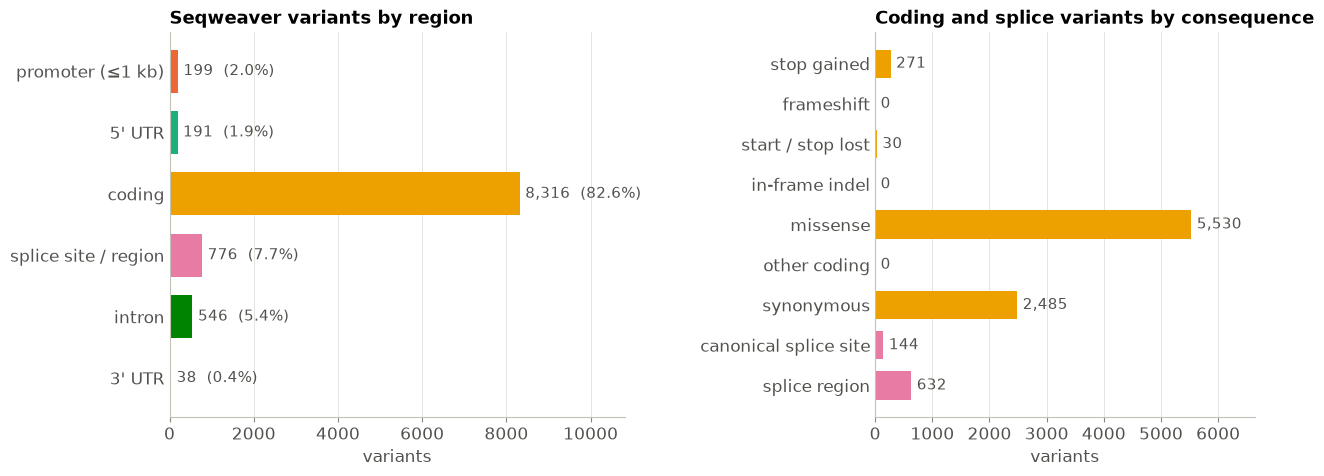

In [15]:
USED_SW = [r for r in USED if (sw.region == r).any()]
sw_plot = sw_overall.loc[USED_SW]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.2, 1], 'wspace': 0.6})
ax.barh(sw_plot.index[::-1], sw_plot.variants[::-1], color=[REGIONS[r] for r in sw_plot.index[::-1]], height=0.7)
ax.bar_label(ax.containers[0], labels=[f'{n:,}  ({p}%)' for n, p in zip(sw_plot.variants[::-1], sw_plot['%'][::-1])],
             padding=4, fontsize=11, color=SECONDARY)
ax.set_title('Seqweaver variants by region')
ax.set_xlabel('variants')
ax.set_xlim(0, sw_plot.variants.max() * 1.3)

sw_detail = (sw[sw.detail.isin(CODING_ORDER + ['canonical splice site', 'splice region'])]
             .detail.value_counts().reindex(CODING_ORDER + ['canonical splice site', 'splice region']).fillna(0))
colors = [REGIONS['coding']] * len(CODING_ORDER) + [REGIONS['splice site / region']] * 2
ax2.barh(sw_detail.index[::-1], sw_detail[::-1], color=colors[::-1], height=0.7)
ax2.bar_label(ax2.containers[0], labels=[f'{int(n):,}' for n in sw_detail[::-1]], padding=4, fontsize=11,
              color=SECONDARY)
ax2.set_title('Coding and splice variants by consequence')
ax2.set_xlabel('variants')
ax2.set_xlim(0, sw_detail.max() * 1.2)
for a in (ax, ax2):
    a.grid(axis='x', color=GRID, lw=0.6)
    a.set_axisbelow(True)
    a.tick_params(axis='y', length=0)
save(fig, 'seqweaver_variants_by_region_and_consequence')

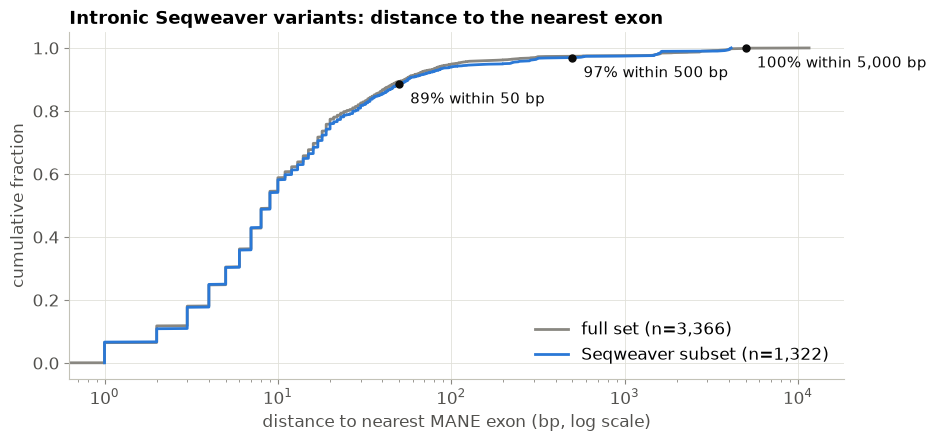

In [16]:
# How deep into introns? Seqweaver subset vs the full set.
fig, ax = plt.subplots(figsize=(10, 4.5))
for df, label, color in [(ann, 'full set', MUTED), (sw, 'Seqweaver subset', BLUE)]:
    d = np.sort(df.exon_distance.dropna().values)
    ax.plot(d, np.arange(1, len(d) + 1) / len(d), color=color, lw=2, label=f'{label} (n={len(d):,})')
d = np.sort(sw.exon_distance.dropna().values)
for x in (50, 500, 5000):
    frac = (d <= x).mean()
    ax.annotate(f'{frac:.0%} within {x:,} bp', (x, frac), xytext=(8, -14), textcoords='offset points',
                fontsize=11, color=INK)
    ax.plot(x, frac, 'o', color=INK, ms=5)
ax.set_xscale('log')
ax.set_xlabel('distance to nearest MANE exon (bp, log scale)')
ax.set_ylabel('cumulative fraction')
ax.grid(color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower right')
ax.set_title('Intronic Seqweaver variants: distance to the nearest exon')
save(fig, 'seqweaver_intronic_distance_to_exon')

### Summary (Seqweaver subset)

- 10,066 variants, all SNVs, in 32 of the 34 BRIDGES genes (none in FANCC or PIK3CA).
- Mostly coding (82.6%: 5,530 missense, 2,485 synonymous, 271 stop gained, 30 start/stop lost). There are no
  frameshifts or in-frame indels because the set has only SNVs.
- 17.4% non-coding: 776 splice site / region, 546 intron, 199 promoter, 191 5' UTR, 38 3' UTR; none distal.
  Nearly all of the full set's promoter and 5' UTR variants are in this subset, so their share is about twice as high.
- Intronic variants are just as exon-adjacent as in the full set (89% within 50 bp of an exon).
- A few genes are much more non-coding than in the full set: BRCA1 (61% non-coding vs 18%), PTEN (54% vs 23%),
  MLH1 (40% vs 26%).

In [17]:
# Per-variant annotation table (hg38 position, gene, region, consequence, distances).
ann.to_csv(ROOT / 'results/bridges34_new_variants_annotated.csv', index=False)